# PROYECTO DE GRADO II - UNAD
Modelo predictivo de bajo peso al nacer

## ETAPA 2: COMPRENSIÓN DE LOS DATOS
Metodología: CRISP-DM

**Objetivo:**
Realizar el diagnóstico inicial del dataset antes de ejecutar la limpieza y preparación definitiva.

ETAPA 2 - COMPRENSIÓN DE LOS DATOS

Dataset cargado correctamente.
Registros: 9,513
Variables: 51

3. INFORMACIÓN GENERAL

Dimensiones:
(9513, 51)

Primeros cinco registros:
   COD_DPTO  COD_MUNIC  AREANAC  COD_INSP  SIT_PARTO OTRO_SIT  \
0        17          1        1       NaN          1      NaN   
1        17          1        1       NaN          1      NaN   
2        17          1        1       NaN          1      NaN   
3        17          1        1       NaN          1      NaN   
4        17          1        1       NaN          1      NaN   

                                            NOM_INST         COD_INST  \
0                              CLIN═CA VERSALLES S.A  170.010.048.801   
1  HERMANAS DE LA CARIDAD DOMINICAS DE LA PRESENT...  170.010.089.201   
2                      SERVICIOS ESPECIALES DE SALUD  170.010.010.301   
3                      SERVICIOS ESPECIALES DE SALUD  170.010.010.301   
4                               CLINICA SAN CAYETANO  170.010.081.704 

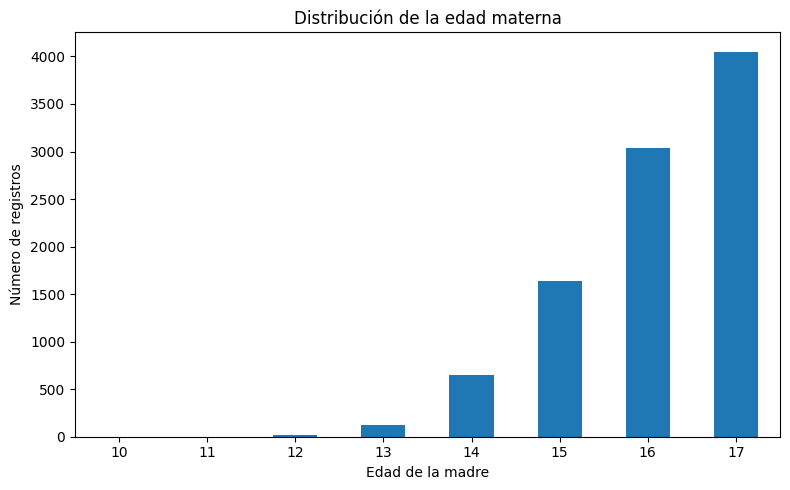

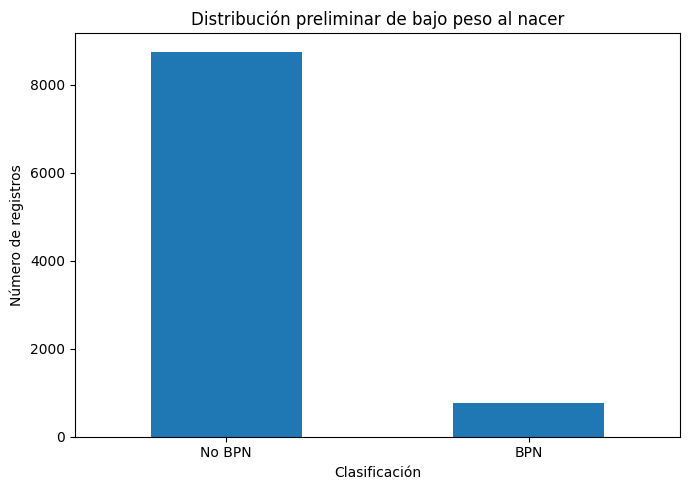

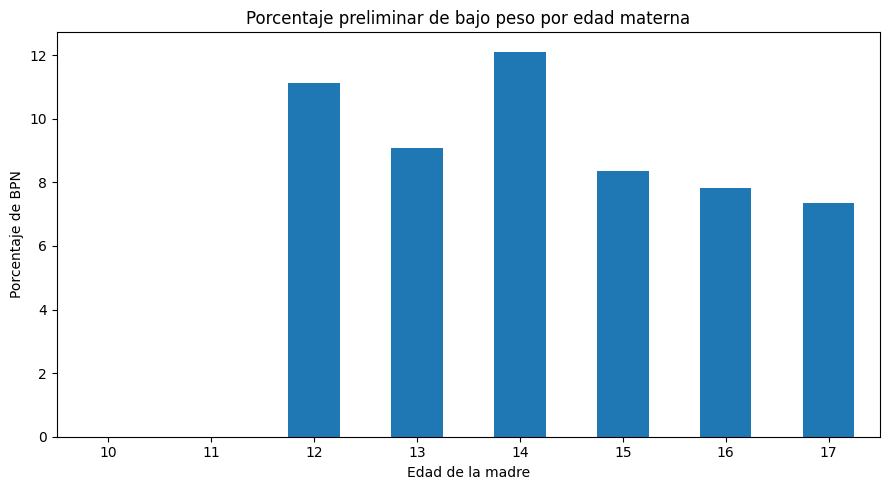

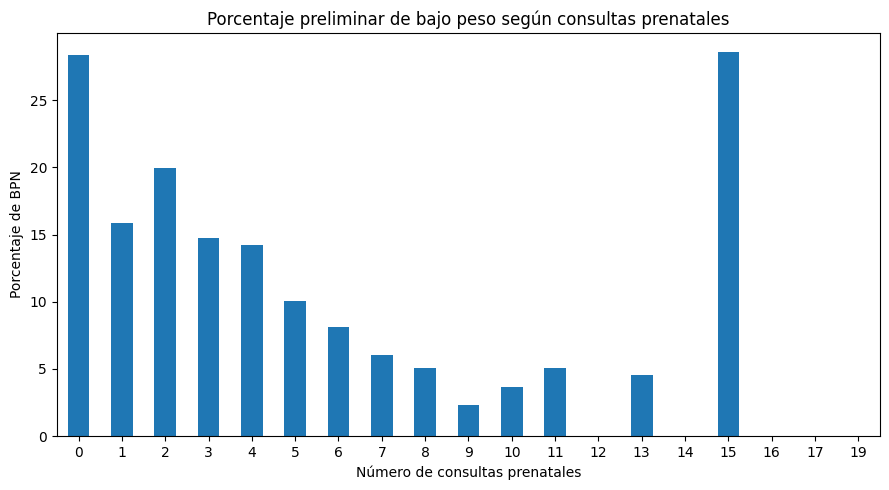




RESUMEN DE LA ETAPA 2

Registros analizados: 9,513
Variables analizadas: 51
Registros duplicados: 0

Edad materna:
  Mínima: 10
  Máxima: 17
  Mediana: 16.0

PESO_NAC:
  Valor especial 9.999: 11
  Pesos utilizables preliminarmente:
      9,502

BAJO_PESO preliminar:
  BPN: 762
  No BPN: 8,740
  Total válido: 9,502

NUMCONSUL:
  Código especial 99: 72

Los resultados detallados fueron exportados a:
  resultados_etapa_2/

FIN DE LA ETAPA 2


In [1]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
import os

# Visualización
import matplotlib.pyplot as plt


# ============================================================
# 2. CARGA DEL DATASET
# ============================================================

# Ruta del archivo CSV
ruta_archivo = "Embarazo_en_adolescentes_20260908.csv"

# Cargar datos
df = pd.read_csv(ruta_archivo)

print("=" * 70)
print("ETAPA 2 - COMPRENSIÓN DE LOS DATOS")
print("=" * 70)

print("\nDataset cargado correctamente.")
print(f"Registros: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")


# ============================================================
# 3. INFORMACIÓN GENERAL
# ============================================================

print("\n" + "=" * 70)
print("3. INFORMACIÓN GENERAL")
print("=" * 70)

print("\nDimensiones:")
print(df.shape)

print("\nPrimeros cinco registros:")
print(df.head())

print("\nÚltimos cinco registros:")
print(df.tail())

print("\nNombres de las variables:")
for i, columna in enumerate(df.columns, start=1):
    print(f"{i:02d}. {columna}")


# ============================================================
# 4. TIPOS DE DATOS
# ============================================================

print("\n" + "=" * 70)
print("4. TIPOS DE DATOS")
print("=" * 70)

tipos_datos = pd.DataFrame({
    "Variable": df.columns,
    "Tipo_dato": df.dtypes.astype(str).values,
    "No_nulos": df.notna().sum().values,
    "Nulos": df.isna().sum().values,
    "Porcentaje_nulos": (
        df.isna().mean().values * 100
    ).round(2)
})

print(tipos_datos.to_string(index=False))


# ============================================================
# 5. REGISTROS DUPLICADOS
# ============================================================

print("\n" + "=" * 70)
print("5. REGISTROS DUPLICADOS")
print("=" * 70)

duplicados = df.duplicated().sum()

print(f"Registros duplicados: {duplicados}")

if duplicados == 0:
    print("No se encontraron registros completamente duplicados.")
else:
    print("Se encontraron registros duplicados que deberán revisarse.")


# ============================================================
# 6. PERFIL DE DATOS FALTANTES
# ============================================================

print("\n" + "=" * 70)
print("6. DATOS FALTANTES")
print("=" * 70)

faltantes = pd.DataFrame({
    "Variable": df.columns,
    "Faltantes": df.isna().sum().values,
    "Porcentaje_faltantes": (
        df.isna().mean().values * 100
    ).round(2)
})

# Ordenar de mayor a menor cantidad de faltantes
faltantes = faltantes.sort_values(
    by="Faltantes",
    ascending=False
)

print(faltantes.to_string(index=False))


# ============================================================
# 7. VARIABLES CON MAYOR AUSENCIA
# ============================================================

print("\n" + "=" * 70)
print("7. VARIABLES CON MAYOR PORCENTAJE DE FALTANTES")
print("=" * 70)

top_faltantes = faltantes[
    faltantes["Faltantes"] > 0
].head(15)

print(top_faltantes.to_string(index=False))


# ============================================================
# 8. RESUMEN ESTADÍSTICO
# ============================================================

print("\n" + "=" * 70)
print("8. RESUMEN ESTADÍSTICO")
print("=" * 70)

print("\nVariables numéricas:")

resumen_numerico = df.describe().T

resumen_numerico["missing"] = df.isna().sum()

print(resumen_numerico)


# ============================================================
# 9. EDAD DE LA MADRE
# ============================================================

print("\n" + "=" * 70)
print("9. EDAD DE LA MADRE")
print("=" * 70)

print("\nDescripción estadística:")
print(df["EDAD_MADRE"].describe())

print("\nDistribución de edad:")
print(
    df["EDAD_MADRE"]
    .value_counts()
    .sort_index()
)

print(
    f"\nEdad mínima: {df['EDAD_MADRE'].min()}"
)

print(
    f"Edad máxima: {df['EDAD_MADRE'].max()}"
)

print(
    f"Mediana: {df['EDAD_MADRE'].median()}"
)


# ============================================================
# 10. EXPLORACIÓN DE PESO AL NACER
# ============================================================

print("\n" + "=" * 70)
print("10. EXPLORACIÓN DE PESO AL NACER")
print("=" * 70)

print("\nDescripción original de PESO_NAC:")
print(df["PESO_NAC"].describe())

print("\nValores más frecuentes:")
print(
    df["PESO_NAC"]
    .value_counts(dropna=False)
    .head(20)
)


# ============================================================
# 11. IDENTIFICACIÓN DEL VALOR ESPECIAL 9.999
# ============================================================

print("\n" + "=" * 70)
print("11. VALOR ESPECIAL EN PESO_NAC")
print("=" * 70)

valor_especial_peso = 9.999

cantidad_9999 = (
    df["PESO_NAC"] == valor_especial_peso
).sum()

print(
    f"Registros con PESO_NAC = {valor_especial_peso}: "
    f"{cantidad_9999}"
)


# ============================================================
# 12. NORMALIZACIÓN PRELIMINAR DEL PESO
# ============================================================
#
# IMPORTANTE:
# Esta transformación es SOLO EXPLORATORIA.
#
# La regla definitiva deberá verificarse contra el
# diccionario/metadatos de la fuente antes de utilizarla
# como transformación definitiva.
#
# Regla preliminar:
#   PESO <= 10  --> se interpreta como kilogramos
#   PESO > 10   --> se interpreta como gramos
#   PESO = 9.999 --> valor especial/no disponible
# ============================================================

peso_preliminar = df["PESO_NAC"].copy()

# Crear variable de peso normalizado
df["PESO_NAC_G_PRELIMINAR"] = np.nan

# Valores especiales
mascara_especial = peso_preliminar == 9.999

# Valores interpretados preliminarmente como kilogramos
mascara_kg = (
    (peso_preliminar <= 10)
    & (~mascara_especial)
    & (peso_preliminar.notna())
)

# Valores interpretados preliminarmente como gramos
mascara_g = (
    (peso_preliminar > 10)
    & (peso_preliminar.notna())
)

# Conversión
df.loc[
    mascara_kg,
    "PESO_NAC_G_PRELIMINAR"
] = (
    peso_preliminar[mascara_kg] * 1000
)

df.loc[
    mascara_g,
    "PESO_NAC_G_PRELIMINAR"
] = peso_preliminar[mascara_g]

print(
    "\nRegistros con peso utilizable:",
    df["PESO_NAC_G_PRELIMINAR"].notna().sum()
)

print(
    "Registros sin peso utilizable:",
    df["PESO_NAC_G_PRELIMINAR"].isna().sum()
)


# ============================================================
# 13. REVISIÓN DE RANGOS DEL PESO NORMALIZADO
# ============================================================

print("\n" + "=" * 70)
print("13. PESO NORMALIZADO - REVISIÓN DE RANGOS")
print("=" * 70)

print(
    df["PESO_NAC_G_PRELIMINAR"].describe()
)

print("\nPesos mínimos:")
print(
    df["PESO_NAC_G_PRELIMINAR"]
    .nsmallest(20)
)

print("\nPesos máximos:")
print(
    df["PESO_NAC_G_PRELIMINAR"]
    .nlargest(20)
)


# ============================================================
# 14. CONSTRUCCIÓN PRELIMINAR DE BAJO_PESO
# ============================================================
#
# Definición operativa preliminar:
#
# BAJO_PESO = 1 si peso < 2500 gramos
# BAJO_PESO = 0 si peso >= 2500 gramos
#
# Los pesos no utilizables permanecen como NaN.
# ============================================================

df["BAJO_PESO_PRELIMINAR"] = np.where(
    df["PESO_NAC_G_PRELIMINAR"].isna(),
    np.nan,
    np.where(
        df["PESO_NAC_G_PRELIMINAR"] < 2500,
        1,
        0
    )
)

print("\n" + "=" * 70)
print("14. VARIABLE OBJETIVO PRELIMINAR")
print("=" * 70)

print(
    df["BAJO_PESO_PRELIMINAR"]
    .value_counts(dropna=False)
    .sort_index()
)


# ============================================================
# 15. DISTRIBUCIÓN DE BAJO PESO
# ============================================================

casos_bpn = (
    df["BAJO_PESO_PRELIMINAR"] == 1
).sum()

casos_no_bpn = (
    df["BAJO_PESO_PRELIMINAR"] == 0
).sum()

casos_validos = (
    df["BAJO_PESO_PRELIMINAR"]
    .notna()
    .sum()
)

print(f"\nCasos BPN: {casos_bpn:,}")
print(f"Casos no BPN: {casos_no_bpn:,}")
print(f"Total con peso utilizable: {casos_validos:,}")

if casos_validos > 0:

    porcentaje_bpn = (
        casos_bpn / casos_validos
    ) * 100

    porcentaje_no_bpn = (
        casos_no_bpn / casos_validos
    ) * 100

    print(
        f"Porcentaje BPN: {porcentaje_bpn:.2f}%"
    )

    print(
        f"Porcentaje no BPN: {porcentaje_no_bpn:.2f}%"
    )


# ============================================================
# 16. DISTRIBUCIÓN DE BPN POR EDAD MATERNA
# ============================================================

print("\n" + "=" * 70)
print("16. BPN POR EDAD MATERNA")
print("=" * 70)

tabla_edad_bpn = (
    df[df["BAJO_PESO_PRELIMINAR"].notna()]
    .groupby("EDAD_MADRE")
    .agg(
        Registros=("BAJO_PESO_PRELIMINAR", "size"),
        BPN=("BAJO_PESO_PRELIMINAR", "sum")
    )
)

tabla_edad_bpn["No_BPN"] = (
    tabla_edad_bpn["Registros"]
    - tabla_edad_bpn["BPN"]
)

tabla_edad_bpn["Porcentaje_BPN"] = (
    tabla_edad_bpn["BPN"]
    / tabla_edad_bpn["Registros"]
    * 100
).round(2)

print(tabla_edad_bpn)


# ============================================================
# 17. EXPLORACIÓN DE NUMCONSUL
# ============================================================

print("\n" + "=" * 70)
print("17. CONSULTAS PRENATALES - NUMCONSUL")
print("=" * 70)

print("\nValores de NUMCONSUL:")
print(
    df["NUMCONSUL"]
    .value_counts(dropna=False)
    .sort_index()
)


# Identificar valor especial 99
cantidad_numconsul_99 = (
    df["NUMCONSUL"] == 99
).sum()

print(
    f"\nRegistros con NUMCONSUL = 99: "
    f"{cantidad_numconsul_99}"
)

print(
    "\nNOTA: El valor 99 se considera un código especial "
    "pendiente de verificación y no debe interpretarse "
    "automáticamente como 99 consultas."
)


# ============================================================
# 18. BPN SEGÚN NÚMERO DE CONSULTAS PRENATALES
# ============================================================
#
# Se excluye temporalmente NUMCONSUL = 99.
#
# Esta tabla es DESCRIPTIVA.
# No representa causalidad.
# ============================================================

df_numconsul = df[
    (df["NUMCONSUL"] != 99)
    & (df["NUMCONSUL"].notna())
    & (df["BAJO_PESO_PRELIMINAR"].notna())
].copy()

tabla_numconsul = (
    df_numconsul
    .groupby("NUMCONSUL")
    .agg(
        Registros=("BAJO_PESO_PRELIMINAR", "size"),
        BPN=("BAJO_PESO_PRELIMINAR", "sum")
    )
)

tabla_numconsul["No_BPN"] = (
    tabla_numconsul["Registros"]
    - tabla_numconsul["BPN"]
)

tabla_numconsul["Porcentaje_BPN"] = (
    tabla_numconsul["BPN"]
    / tabla_numconsul["Registros"]
    * 100
).round(2)

print("\nTabla de NUMCONSUL:")
print(tabla_numconsul)


# ============================================================
# 19. REVISIÓN DE VARIABLES CATEGÓRICAS
# ============================================================

print("\n" + "=" * 70)
print("19. VARIABLES CATEGÓRICAS - NÚMERO DE CATEGORÍAS")
print("=" * 70)

variables_categoricas = df.select_dtypes(
    include=["object", "category"]
).columns

for columna in variables_categoricas:

    print(
        f"\n{columna}: "
        f"{df[columna].nunique(dropna=True)} "
        "categorías únicas"
    )

    print(
        df[columna]
        .value_counts(dropna=False)
        .head(10)
    )


# ============================================================
# 20. VARIABLES CON MUCHAS CATEGORÍAS
# ============================================================

print("\n" + "=" * 70)
print("20. CARDINALIDAD DE LAS VARIABLES")
print("=" * 70)

cardinalidad = pd.DataFrame({
    "Variable": df.columns,
    "Valores_unicos": [
        df[col].nunique(dropna=True)
        for col in df.columns
    ]
})

cardinalidad = cardinalidad.sort_values(
    by="Valores_unicos",
    ascending=False
)

print(cardinalidad.to_string(index=False))


# ============================================================
# 21. REVISIÓN DE VARIABLES CANDIDATAS
# ============================================================

variables_candidatas = [
    "EDAD_MADRE",
    "EST_CIVM",
    "NIV_EDUM",
    "N_HIJOSV",
    "N_EMB",
    "SEG_SOCIAL",
    "AREA_RES",
    "IDPUEBLOIN",
    "EDAD_PADRE",
    "NIV_EDUP",
    "NUMCONSUL",
    "COD_DPTO",
    "COD_MUNIC",
    "CODPTORE",
    "CODMUNRE"
]

print("\n" + "=" * 70)
print("21. PERFIL DE VARIABLES CANDIDATAS")
print("=" * 70)

perfil_candidatas = []

for variable in variables_candidatas:

    perfil_candidatas.append({
        "Variable": variable,
        "Tipo": str(df[variable].dtype),
        "No_nulos": df[variable].notna().sum(),
        "Faltantes": df[variable].isna().sum(),
        "%_faltantes": round(
            df[variable].isna().mean() * 100,
            2
        ),
        "Valores_unicos": df[variable].nunique(
            dropna=True
        )
    })

perfil_candidatas = pd.DataFrame(
    perfil_candidatas
)

print(
    perfil_candidatas
    .to_string(index=False)
)


# ============================================================
# 22. VARIABLES QUE PUEDEN GENERAR FUGA DE INFORMACIÓN
# ============================================================

print("\n" + "=" * 70)
print("22. REVISIÓN PRELIMINAR DE FUGA DE INFORMACIÓN")
print("=" * 70)

variables_resultado = [
    "PESO_NAC",
    "TALLA_NAC",
    "APGAR1",
    "APGAR2",
    "TIPO_PARTO"
]

for variable in variables_resultado:

    if variable in df.columns:

        print(
            f"- {variable}: revisar/excluir del conjunto "
            "predictor principal por disponibilidad temporal."
        )


if "T_GES" in df.columns:

    print(
        "- T_GES: revisar temporalidad antes de incluirla "
        "en el modelo principal."
    )

print("\n")
# ============================================================
# 23. VISUALIZACIÓN: DISTRIBUCIÓN DE EDAD MATERNA
# ============================================================

plt.figure(figsize=(8, 5))

df["EDAD_MADRE"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribución de la edad materna")
plt.xlabel("Edad de la madre")
plt.ylabel("Número de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n")
# ============================================================
# 24. VISUALIZACIÓN: DISTRIBUCIÓN DE BAJO PESO
# ============================================================

frecuencia_bpn = (
    df["BAJO_PESO_PRELIMINAR"]
    .map({
        0: "No BPN",
        1: "BPN"
    })
    .value_counts()
)

plt.figure(figsize=(7, 5))

frecuencia_bpn.plot(
    kind="bar"
)

plt.title(
    "Distribución preliminar de bajo peso al nacer"
)

plt.xlabel("Clasificación")
plt.ylabel("Número de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n")
# ============================================================
# 25. VISUALIZACIÓN: BPN POR EDAD MATERNA
# ============================================================

plt.figure(figsize=(9, 5))

tabla_edad_bpn["Porcentaje_BPN"].plot(
    kind="bar"
)

plt.title(
    "Porcentaje preliminar de bajo peso por edad materna"
)

plt.xlabel("Edad de la madre")
plt.ylabel("Porcentaje de BPN")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n")
# ============================================================
# 26. VISUALIZACIÓN: BPN SEGÚN CONSULTAS PRENATALES
# ============================================================

plt.figure(figsize=(9, 5))

tabla_numconsul["Porcentaje_BPN"].plot(
    kind="bar"
)

plt.title(
    "Porcentaje preliminar de bajo peso según consultas prenatales"
)

plt.xlabel("Número de consultas prenatales")
plt.ylabel("Porcentaje de BPN")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n")
# ============================================================
# 27. EXPORTACIÓN DE RESULTADOS DE LA ETAPA 2
# ============================================================

# Crear carpeta de resultados
carpeta_resultados = "resultados_etapa_2"

os.makedirs(
    carpeta_resultados,
    exist_ok=True
)

# Exportar perfil general
tipos_datos.to_csv(
    os.path.join(
        carpeta_resultados,
        "01_perfil_variables.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# Exportar faltantes
faltantes.to_csv(
    os.path.join(
        carpeta_resultados,
        "02_datos_faltantes.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# Exportar resumen numérico
resumen_numerico.to_csv(
    os.path.join(
        carpeta_resultados,
        "03_resumen_numerico.csv"
    ),
    encoding="utf-8-sig"
)

# Exportar tabla de edad y BPN
tabla_edad_bpn.to_csv(
    os.path.join(
        carpeta_resultados,
        "04_bpn_por_edad_materna.csv"
    ),
    encoding="utf-8-sig"
)

# Exportar tabla de consultas
tabla_numconsul.to_csv(
    os.path.join(
        carpeta_resultados,
        "05_bpn_por_consultas_prenatales.csv"
    ),
    encoding="utf-8-sig"
)

# Exportar perfil de candidatas
perfil_candidatas.to_csv(
    os.path.join(
        carpeta_resultados,
        "06_perfil_variables_candidatas.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

# Exportar cardinalidad
cardinalidad.to_csv(
    os.path.join(
        carpeta_resultados,
        "07_cardinalidad_variables.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 28. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN DE LA ETAPA 2")
print("=" * 70)

print(f"""
Registros analizados: {df.shape[0]:,}
Variables analizadas: {df.shape[1] - 2:,}
Registros duplicados: {duplicados:,}

Edad materna:
  Mínima: {df['EDAD_MADRE'].min()}
  Máxima: {df['EDAD_MADRE'].max()}
  Mediana: {df['EDAD_MADRE'].median()}

PESO_NAC:
  Valor especial 9.999: {cantidad_9999}
  Pesos utilizables preliminarmente:
      {df['PESO_NAC_G_PRELIMINAR'].notna().sum():,}

BAJO_PESO preliminar:
  BPN: {casos_bpn:,}
  No BPN: {casos_no_bpn:,}
  Total válido: {casos_validos:,}

NUMCONSUL:
  Código especial 99: {cantidad_numconsul_99}

Los resultados detallados fueron exportados a:
  {carpeta_resultados}/
""")

print("=" * 70)
print("FIN DE LA ETAPA 2")
print("=" * 70)

## ETAPA 3 - PREPARACIÓN DE LOS DATOS

In [2]:

# ------------------------------------------------------------
# 1. COPIA DE TRABAJO Y ELIMINACIÓN DE DUPLICADOS
# ------------------------------------------------------------

df_prep = df.copy()

registros_iniciales = len(df_prep)

df_prep = df_prep.drop_duplicates().copy()

registros_finales_sin_duplicados = len(df_prep)
duplicados_eliminados = (
    registros_iniciales - registros_finales_sin_duplicados
)

print("=" * 70)
print("ETAPA 3 - PREPARACIÓN DE LOS DATOS")
print("=" * 70)

print(f"Registros iniciales: {registros_iniciales}")
print(f"Duplicados eliminados: {duplicados_eliminados}")
print(
    f"Registros después de eliminar duplicados: "
    f"{registros_finales_sin_duplicados}"
)


# ------------------------------------------------------------
# 2. CONVERSIÓN DE VARIABLES NUMÉRICAS
# ------------------------------------------------------------

columnas_numericas = [
    "PESO_NAC",
    "EDAD_MADRE",
    "EDAD_PADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES"
]

for columna in columnas_numericas:
    if columna in df_prep.columns:
        df_prep[columna] = pd.to_numeric(
            df_prep[columna],
            errors="coerce"
        )


# ------------------------------------------------------------
# 3. TRANSFORMACIÓN PROVISIONAL DE PESO
# ------------------------------------------------------------

print("""
TRANSFORMACIÓN PROVISIONAL DE PESO
----------------------------------
9.999 -> valor especial/no disponible
<= 10 -> provisionalmente kilogramos
> 10 -> provisionalmente gramos

IMPORTANTE:
Esta regla debe verificarse contra el diccionario oficial
del conjunto de datos antes de considerarla definitiva.
""")

df_prep["PESO_G"] = np.where(
    df_prep["PESO_NAC"] == 9.999,
    np.nan,
    np.where(
        df_prep["PESO_NAC"] <= 10,
        df_prep["PESO_NAC"] * 1000,
        df_prep["PESO_NAC"]
    )
)

print("Resumen de PESO_G:")
display(df_prep["PESO_G"].describe())


# ------------------------------------------------------------
# 4. REVISIÓN DE PESOS EXTREMOS
# ------------------------------------------------------------

print("Pesos más bajos:")

display(
    df_prep[
        ["PESO_NAC", "PESO_G", "EDAD_MADRE", "T_GES"]
    ]
    .sort_values("PESO_G")
    .head(20)
)

print("Pesos más altos:")

display(
    df_prep[
        ["PESO_NAC", "PESO_G", "EDAD_MADRE", "T_GES"]
    ]
    .sort_values("PESO_G", ascending=False)
    .head(20)
)


# ------------------------------------------------------------
# 5. CONSTRUCCIÓN DE LA VARIABLE OBJETIVO
# ------------------------------------------------------------

df_prep["BAJO_PESO"] = np.where(
    df_prep["PESO_G"].isna(),
    np.nan,
    (df_prep["PESO_G"] < 2500).astype(int)
)

df_prep["BAJO_PESO"] = pd.Series(
    df_prep["BAJO_PESO"],
    index=df_prep.index
).astype("Int64")


# ------------------------------------------------------------
# 6. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ------------------------------------------------------------

objetivo = (
    df_prep["BAJO_PESO"]
    .value_counts(dropna=False)
    .to_frame("Frecuencia")
)

objetivo["Porcentaje"] = (
    objetivo["Frecuencia"]
    / len(df_prep)
    * 100
)

print("Distribución de BAJO_PESO:")
display(objetivo)


# ------------------------------------------------------------
# 7. TRATAMIENTO DE CÓDIGOS ESPECIALES
# ------------------------------------------------------------
#
# Estos valores fueron identificados durante el EDA como posibles
# códigos especiales y no deben interpretarse como valores numéricos
# reales.
#
# NUMCONSUL = 99 -> valor faltante
# EDAD_PADRE = 999 -> valor faltante
# T_GES = 99 -> valor faltante
# NIV_EDUM = 99 -> valor faltante
#
# El significado oficial de estos códigos debe verificarse contra
# el diccionario de datos de la fuente.

print("\nTRATAMIENTO DE CÓDIGOS ESPECIALES")

codigos_especiales = {
    "NUMCONSUL": [99],
    "EDAD_PADRE": [99, 999],
    "T_GES": [98, 99],
    "NIV_EDUM": [99]
}

for variable, codigos in codigos_especiales.items():

    if variable in df_prep.columns:

        for codigo in codigos:

            cantidad = (
                df_prep[variable] == codigo
            ).sum()

            print(
                f"{variable} = {codigo}: "
                f"{cantidad} registros"
            )

            df_prep.loc[
                df_prep[variable] == codigo,
                variable
            ] = np.nan


# ------------------------------------------------------------
# 8. REVISIÓN DE VARIABLES DERIVADAS
# ------------------------------------------------------------
#
# Si existen variables derivadas de una ejecución anterior,
# se eliminan para evitar duplicidad o fuga de información.
#
# Estas variables no son predictores independientes porque se
# derivan directamente del peso o de la variable objetivo.

variables_derivadas_no_predictoras = [
    "PESO_NAC_G_PRELIMINAR",
    "BAJO_PESO_PRELIMINAR"
]

variables_derivadas_existentes = [
    v for v in variables_derivadas_no_predictoras
    if v in df_prep.columns
]

if variables_derivadas_existentes:

    print("\nVARIABLES DERIVADAS DETECTADAS Y EXCLUIDAS:")

    for variable in variables_derivadas_existentes:
        print(f"- {variable}")

    df_prep = df_prep.drop(
        columns=variables_derivadas_existentes
    )


# ------------------------------------------------------------
# 9. VARIABLES EXCLUIDAS DEL MODELO PRINCIPAL
# ------------------------------------------------------------

variables_excluir = [
    "PESO_NAC",
    "PESO_G",
    "TALLA_NAC",
    "APGAR1",
    "APGAR2",
    "TIPO_PARTO",
    "FECHA_NAC",
    "FECHA_EXP"
]

variables_excluir = [
    v for v in variables_excluir
    if v in df_prep.columns
]


# ------------------------------------------------------------
# 10. JUSTIFICACIÓN DE LAS EXCLUSIONES
# ------------------------------------------------------------

justificacion_exclusiones = {

    "PESO_NAC":
        "Se utiliza para construir la variable objetivo BAJO_PESO.",

    "PESO_G":
        "Es la transformación de PESO_NAC utilizada para construir "
        "BAJO_PESO.",

    "TALLA_NAC":
        "Contiene información correspondiente al recién nacido.",

    "APGAR1":
        "Contiene información generada durante el nacimiento.",

    "APGAR2":
        "Contiene información generada durante el nacimiento.",

    "TIPO_PARTO":
        "Corresponde a una característica del nacimiento y puede "
        "generar fuga de información.",

    "FECHA_NAC":
        "Corresponde al momento del nacimiento y no constituye "
        "una variable predictora prenatal.",

    "FECHA_EXP":
        "No se considera necesaria para la predicción del bajo peso."
}


print("\nVARIABLES EXCLUIDAS DEL MODELO PRINCIPAL:")

for variable in variables_excluir:

    print(
        f"- {variable}: "
        f"{justificacion_exclusiones.get(variable, 'Revisar')}"
    )


# ------------------------------------------------------------
# 11. VARIABLES QUE REQUIEREN REVISIÓN TEMPORAL
# ------------------------------------------------------------
#
# Se conservan temporalmente porque su inclusión depende del momento
# exacto en que se pretende realizar la predicción.

variables_revisar = [
    "T_GES",
    "SIT_PARTO",
    "ATEN_PAR",
    "MUL_PARTO"
]

variables_revisar = [
    v for v in variables_revisar
    if v in df_prep.columns
]

print("\nVARIABLES QUE REQUIEREN REVISIÓN TEMPORAL:")

for variable in variables_revisar:
    print(f"- {variable}")


# ------------------------------------------------------------
# 12. CONSTRUCCIÓN DEL DATASET ANALÍTICO PRELIMINAR
# ------------------------------------------------------------

df_modelo = df_prep.drop(
    columns=variables_excluir
).copy()


# ------------------------------------------------------------
# 13. ELIMINACIÓN DE REGISTROS SIN VARIABLE OBJETIVO
# ------------------------------------------------------------

registros_sin_objetivo = (
    df_modelo["BAJO_PESO"].isna()
).sum()

df_modelo = df_modelo[
    df_modelo["BAJO_PESO"].notna()
].copy()

df_modelo["BAJO_PESO"] = (
    df_modelo["BAJO_PESO"]
    .astype(int)
)


# ------------------------------------------------------------
# 14. REVISIÓN DE FALTANTES
# ------------------------------------------------------------

faltantes = pd.DataFrame({
    "Variable": df_modelo.columns,
    "Faltantes": df_modelo.isna().sum()
})

faltantes["Porcentaje"] = (
    faltantes["Faltantes"]
    / len(df_modelo)
    * 100
)

faltantes = faltantes.sort_values(
    "Porcentaje",
    ascending=False
)


# ------------------------------------------------------------
# 15. RESULTADO DE LA PREPARACIÓN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESULTADO DE LA PREPARACIÓN")
print("=" * 70)

print(f"Registros iniciales: {registros_iniciales}")
print(f"Duplicados eliminados: {duplicados_eliminados}")
print(
    f"Registros sin variable objetivo eliminados: "
    f"{registros_sin_objetivo}"
)
print(f"Registros finales: {len(df_modelo)}")
print(f"Variables finales: {df_modelo.shape[1]}")

print("\nDistribución final de BAJO_PESO:")

display(
    df_modelo["BAJO_PESO"]
    .value_counts()
    .sort_index()
    .to_frame("Frecuencia")
)

print("\nValores faltantes después de la preparación:")

display(faltantes)


# ------------------------------------------------------------
# 16. VISTA PRELIMINAR
# ------------------------------------------------------------

print("\nPrimeros registros del dataset analítico:")

display(df_modelo.head())


# ------------------------------------------------------------
# 17. EXPORTACIÓN DEL ÚNICO PRODUCTO DE LA ETAPA 3
# ------------------------------------------------------------
#
# El único archivo generado como producto de esta etapa es:
#
# dataset_analitico_bajo_peso.csv
#
# Las tablas de control se muestran en pantalla y no se generan
# como archivos independientes.

df_modelo.to_csv(
    "dataset_analitico_bajo_peso.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("ETAPA 3 FINALIZADA")
print("=" * 70)

print(
    "\nDataset analítico guardado como:"
    "\ndataset_analitico_bajo_peso.csv"
)


ETAPA 3 - PREPARACIÓN DE LOS DATOS
Registros iniciales: 9513
Duplicados eliminados: 0
Registros después de eliminar duplicados: 9513

TRANSFORMACIÓN PROVISIONAL DE PESO
----------------------------------
9.999 -> valor especial/no disponible
<= 10 -> provisionalmente kilogramos
> 10 -> provisionalmente gramos

IMPORTANTE:
Esta regla debe verificarse contra el diccionario oficial
del conjunto de datos antes de considerarla definitiva.

Resumen de PESO_G:


,PESO_G
count,9502.000000
mean,3110.022837
std,493.646410
min,360.000000
25%,2855.000000
50%,3130.000000
75%,3410.000000
max,5174.000000


Pesos más bajos:


,PESO_NAC,PESO_G,EDAD_MADRE,T_GES
8756,360.0,360.0,17,20
4654,500.0,500.0,17,23
4655,522.0,522.0,17,23
5561,530.0,530.0,12,21
4627,536.0,536.0,17,22
5223,550.0,550.0,16,23
6370,550.0,550.0,17,23
866,600.0,600.0,15,23
3762,610.0,610.0,16,31
71,610.0,610.0,14,24


Pesos más altos:


,PESO_NAC,PESO_G,EDAD_MADRE,T_GES
3574,5.174,5174.0,16,40
6824,5.000,5000.0,16,41
4559,4.900,4900.0,15,41
4034,4.820,4820.0,17,39
6406,4.805,4805.0,15,40
2218,4.800,4800.0,17,37
6465,4.700,4700.0,14,39
3592,4.616,4616.0,17,41
2878,4.600,4600.0,17,41
6442,4.600,4600.0,17,40


... (5 outputs left out)

,Variable,Faltantes,Porcentaje
OTRO_SIT,OTRO_SIT,9482,99.789518
OTRPARATX,OTRPARATX,9482,99.789518
COD_INSP,COD_INSP,9402,98.947590
NOM_PUEB,NOM_PUEB,8972,94.422227
VEREDAMAD,VEREDAMAD,6819,71.763839
BARRMADRE,BARRMADRE,3643,38.339297
FECHA_NACM,FECHA_NACM,1700,17.890970
EDAD_PADRE,EDAD_PADRE,264,2.778362
IDCLASADMI,IDCLASADMI,238,2.504736
NOMCLASAD,NOMCLASAD,238,2.504736



Primeros registros del dataset analítico:


,COD_DPTO,COD_MUNIC,AREANAC,COD_INSP,SIT_PARTO,OTRO_SIT,NOM_INST,COD_INST,SEXO,ANO,...,SEG_SOCIAL,IDCLASADMI,NOMCLASAD,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,IDDEPTOEXP,IDMUNICEXP,BAJO_PESO
0,17,1,1,NaN,1,NaN,CLIN═CA VERSALLES S.A,170.010.048.801,FEMENINO,2.01,...,2,2.0,CAPRECOM - CAJA DE PREVISION SOCIAL DE COMUNIC...,16.0,99,99,1,17,1,0
1,17,1,1,NaN,1,NaN,HERMANAS DE LA CARIDAD DOMINICAS DE LA PRESENT...,170.010.089.201,MASCULINO,2.01,...,1,1.0,SALUDCOOP - ENTIDAD PROMOTORA DE SALUD ORGANIS...,30.0,4,99,1,17,1,0
2,17,1,1,NaN,1,NaN,SERVICIOS ESPECIALES DE SALUD,170.010.010.301,MASCULINO,2.01,...,2,2.0,CAPRECOM - CAJA DE PREVISION SOCIAL DE COMUNIC...,19.0,4,11,1,17,1,0
3,17,1,1,NaN,1,NaN,SERVICIOS ESPECIALES DE SALUD,170.010.010.301,FEMENINO,2.01,...,2,2.0,CALISALUD - ENTIDAD PROMOTORA DE SALUD,22.0,99,99,1,17,1,0
4,17,1,1,NaN,1,NaN,CLINICA SAN CAYETANO,170.010.081.704,FEMENINO,2.01,...,2,2.0,COOSALUD E.S.S. ARS - COOPERATIVA EMPRESA SOLI...,25.0,99,99,1,17,1,1



ETAPA 3 FINALIZADA

Dataset analítico guardado como:
dataset_analitico_bajo_peso.csv


## ETAPA 4 - ANÁLISIS EXPLORATORIO DE DATOS (EDA)

ETAPA 4 - ANÁLISIS EXPLORATORIO DE DATOS

Dimensiones del dataset:
Registros: 9502
Variables: 45

Primeros registros:


,COD_DPTO,COD_MUNIC,AREANAC,COD_INSP,SIT_PARTO,OTRO_SIT,NOM_INST,COD_INST,SEXO,ANO,...,SEG_SOCIAL,IDCLASADMI,NOMCLASAD,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,IDDEPTOEXP,IDMUNICEXP,BAJO_PESO
0,17,1,1,NaN,1,NaN,CLIN═CA VERSALLES S.A,170.010.048.801,FEMENINO,2.01,...,2,2.0,CAPRECOM - CAJA DE PREVISION SOCIAL DE COMUNIC...,16.0,99,99,1,17,1,0
1,17,1,1,NaN,1,NaN,HERMANAS DE LA CARIDAD DOMINICAS DE LA PRESENT...,170.010.089.201,MASCULINO,2.01,...,1,1.0,SALUDCOOP - ENTIDAD PROMOTORA DE SALUD ORGANIS...,30.0,4,99,1,17,1,0
2,17,1,1,NaN,1,NaN,SERVICIOS ESPECIALES DE SALUD,170.010.010.301,MASCULINO,2.01,...,2,2.0,CAPRECOM - CAJA DE PREVISION SOCIAL DE COMUNIC...,19.0,4,11,1,17,1,0
3,17,1,1,NaN,1,NaN,SERVICIOS ESPECIALES DE SALUD,170.010.010.301,FEMENINO,2.01,...,2,2.0,CALISALUD - ENTIDAD PROMOTORA DE SALUD,22.0,99,99,1,17,1,0
4,17,1,1,NaN,1,NaN,CLINICA SAN CAYETANO,170.010.081.704,FEMENINO,2.01,...,2,2.0,COOSALUD E.S.S. ARS - COOPERATIVA EMPRESA SOLI...,25.0,99,99,1,17,1,1



3. INFORMACIÓN GENERAL

Tipos de datos:


,Tipo_dato
COD_DPTO,int64
COD_MUNIC,int64
AREANAC,int64
COD_INSP,float64
SIT_PARTO,int64
OTRO_SIT,object
NOM_INST,object
COD_INST,object
SEXO,object
ANO,float64



Valores faltantes:


,Variable,Faltantes,Porcentaje
5,OTRO_SIT,9482,99.789518
14,OTRPARATX,9482,99.789518
3,COD_INSP,9402,98.947590
21,NOM_PUEB,8972,94.422227
31,VEREDAMAD,6819,71.763839
30,BARRMADRE,3643,38.339297
33,FECHA_NACM,1700,17.890970
38,EDAD_PADRE,264,2.778362
36,IDCLASADMI,238,2.504736
37,NOMCLASAD,238,2.504736



5. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO


,Frecuencia,Porcentaje,Categoria
BAJO_PESO,,,
0,8740,91.980636,No bajo peso
1,762,8.019364,Bajo peso


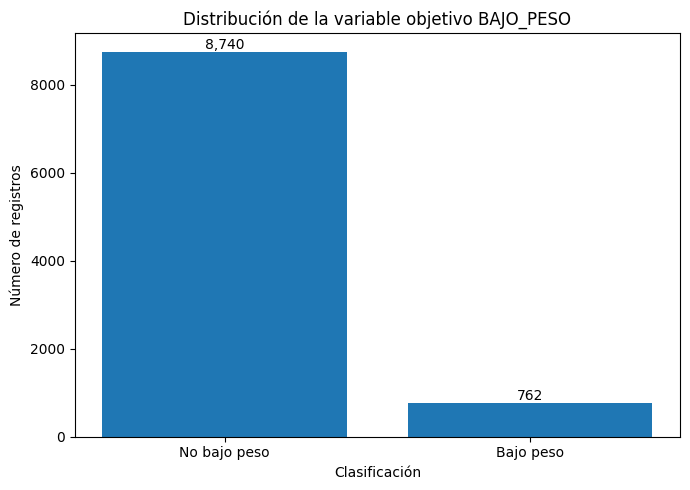


7. ANÁLISIS DE VARIABLES NUMÉRICAS

Variables numéricas analizadas:
['EDAD_MADRE', 'EDAD_PADRE', 'NUMCONSUL', 'N_HIJOSV', 'N_EMB', 'T_GES']


,count,mean,Mediana,std,min,25%,50%,75%,max
EDAD_MADRE,9502.0,16.070827,16.0,1.009133,10.0,15.0,16.0,17.0,17.0
EDAD_PADRE,9238.0,22.447716,21.0,5.554207,13.0,19.0,21.0,25.0,80.0
NUMCONSUL,9435.0,6.408479,7.0,2.256729,0.0,5.0,7.0,8.0,19.0
N_HIJOSV,9502.0,1.062513,1.0,0.251062,1.0,1.0,1.0,1.0,3.0
N_EMB,9502.0,1.090507,1.0,0.318560,1.0,1.0,1.0,1.0,7.0
T_GES,9492.0,38.571007,39.0,2.001873,20.0,38.0,39.0,40.0,42.0



7.1. ANÁLISIS DE VARIABLES NUMÉRICAS MEDIANTE CUARTILES

EDAD_MADRE
Q1: 15.0
Mediana: 16.0
Q3: 17.0
RIC: 2.0
Límite inferior: 12.0
Límite superior: 20.0

EDAD_PADRE
Q1: 19.0
Mediana: 21.0
Q3: 25.0
RIC: 6.0
Límite inferior: 10.0
Límite superior: 34.0

NUMCONSUL
Q1: 5.0
Mediana: 7.0
Q3: 8.0
RIC: 3.0
Límite inferior: 0.5
Límite superior: 12.5

N_HIJOSV
Q1: 1.0
Mediana: 1.0
Q3: 1.0
RIC: 0.0
Límite inferior: 1.0
Límite superior: 1.0

N_EMB
Q1: 1.0
Mediana: 1.0
Q3: 1.0
RIC: 0.0
Límite inferior: 1.0
Límite superior: 1.0

T_GES
Q1: 38.0
Mediana: 39.0
Q3: 40.0
RIC: 2.0
Límite inferior: 35.0
Límite superior: 43.0

Tabla de cuartiles:


,Variable,Q1,Mediana,Q3,RIC,Limite_inferior,Limite_superior
0,EDAD_MADRE,15.0,16.0,17.0,2.0,12.0,20.0
1,EDAD_PADRE,19.0,21.0,25.0,6.0,10.0,34.0
2,NUMCONSUL,5.0,7.0,8.0,3.0,0.5,12.5
3,N_HIJOSV,1.0,1.0,1.0,0.0,1.0,1.0
4,N_EMB,1.0,1.0,1.0,0.0,1.0,1.0
5,T_GES,38.0,39.0,40.0,2.0,35.0,43.0



8. DISTRIBUCIÓN DE EDAD DE LA MADRE


,Frecuencia,Porcentaje
EDAD_MADRE,,
10,1,0.010524
11,2,0.021048
12,18,0.189434
13,121,1.273416
14,644,6.777521
15,1636,17.217428
16,3032,31.909072
17,4048,42.601558


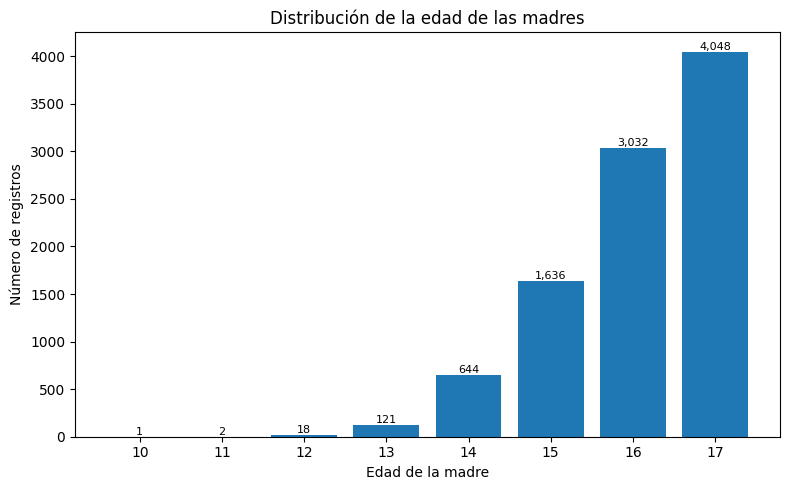


9. BAJO PESO SEGÚN EDAD DE LA MADRE


BAJO_PESO,No_bajo_peso,Bajo_peso,Total,Porcentaje_bajo_peso
EDAD_MADRE,,,,
10,1,0,1,0.000000
11,2,0,2,0.000000
12,16,2,18,11.111111
13,110,11,121,9.090909
14,566,78,644,12.111801
15,1499,137,1636,8.374083
16,2795,237,3032,7.816623
17,3751,297,4048,7.336957


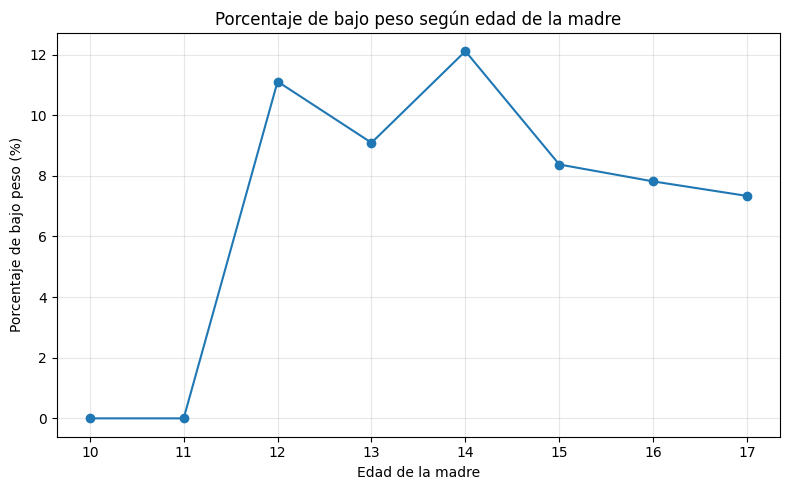


10. DISTRIBUCIÓN DE CONSULTAS PRENATALES


,Frecuencia,Porcentaje
NUMCONSUL,,
0.0,113,1.189223
1.0,177,1.862766
2.0,266,2.799411
3.0,454,4.777941
4.0,753,7.924647
5.0,1114,11.723848
6.0,1323,13.923385
7.0,2297,24.173858
8.0,1493,15.712482


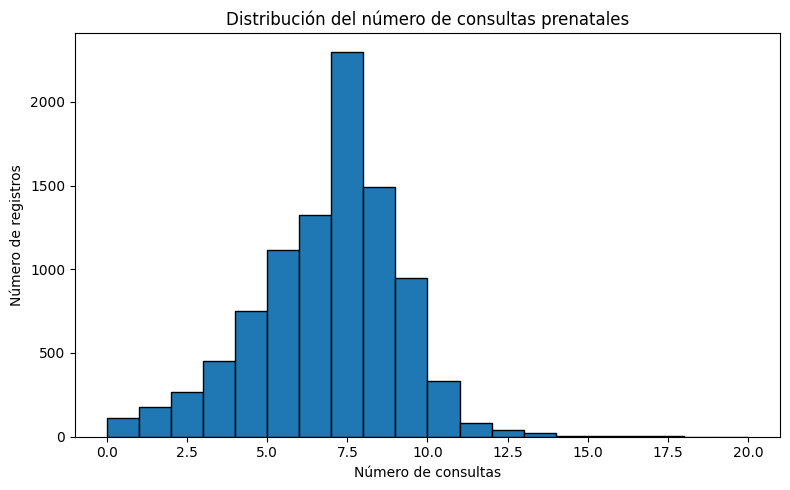


11. BAJO PESO SEGÚN NÚMERO DE CONSULTAS


BAJO_PESO,No_bajo_peso,Bajo_peso,Total,Porcentaje_bajo_peso
NUMCONSUL,,,,
0.0,81,32,113,28.318584
1.0,149,28,177,15.819209
2.0,213,53,266,19.924812
3.0,387,67,454,14.757709
4.0,646,107,753,14.209827
5.0,1002,112,1114,10.053860
6.0,1216,107,1323,8.087680
7.0,2159,138,2297,6.007836
8.0,1417,76,1493,5.090422


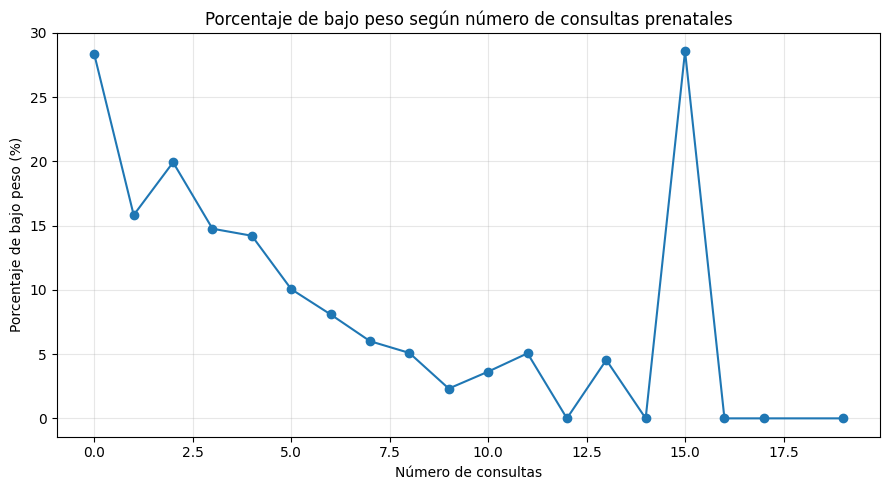


12. VARIABLES CATEGÓRICAS
Variables categóricas:
['OTRO_SIT', 'NOM_INST', 'COD_INST', 'SEXO', 'OTRPARATX', 'NOM_PUEB', 'CODPTORE', 'CODMUNRE', 'BARRMADRE', 'VEREDAMAD', 'FECHA_NACM', 'NOMCLASAD']


,Variable,Categorias_unicas,Faltantes
9,VEREDAMAD,1690,6819
8,BARRMADRE,1502,3643
10,FECHA_NACM,529,1700
2,COD_INST,119,13
1,NOM_INST,114,13
11,NOMCLASAD,94,238
7,CODMUNRE,27,0
4,OTRPARATX,19,9482
5,NOM_PUEB,17,8972
0,OTRO_SIT,10,9482



ANÁLISIS DE EST_CIVM


,Frecuencia,Porcentaje
EST_CIVM,,
5,4326,45.527257
2,3421,36.002947
1,1487,15.649337
6,149,1.568091
9,94,0.989265
3,16,0.168386
4,9,0.094717



ANÁLISIS DE NIV_EDUM


,Frecuencia,Porcentaje
NIV_EDUM,,
3.0,5175,54.462218
2.0,2115,22.258472
4.0,1962,20.648285
NaN,139,1.462850
13.0,46,0.484109
5.0,40,0.420964
1.0,21,0.221006
9.0,3,0.031572
8.0,1,0.010524


... (10 outputs left out)


BAJO PESO SEGÚN SEG_SOCIAL


BAJO_PESO,No_bajo_peso,Bajo_peso,Total,Porcentaje_bajo_peso
SEG_SOCIAL,,,,
1,2005,166,2171,7.646246
2,6406,559,6965,8.025844
3,111,12,123,9.756098
4,5,0,5,0.000000
5,213,25,238,10.504202



16. CORRELACIÓN ENTRE VARIABLES NUMÉRICAS


,EDAD_MADRE,EDAD_PADRE,NUMCONSUL,N_HIJOSV,N_EMB,T_GES,BAJO_PESO
EDAD_MADRE,1.000000,0.134309,0.071266,0.131663,0.141797,0.070754,-0.034933
EDAD_PADRE,0.134309,1.000000,-0.019336,0.091865,0.084537,0.042078,-0.016696
NUMCONSUL,0.071266,-0.019336,1.000000,-0.133464,-0.093327,0.244954,-0.160899
N_HIJOSV,0.131663,0.091865,-0.133464,1.000000,0.738596,-0.059527,0.057673
N_EMB,0.141797,0.084537,-0.093327,0.738596,1.000000,-0.011302,0.012205
T_GES,0.070754,0.042078,0.244954,-0.059527,-0.011302,1.000000,-0.581321
BAJO_PESO,-0.034933,-0.016696,-0.160899,0.057673,0.012205,-0.581321,1.000000


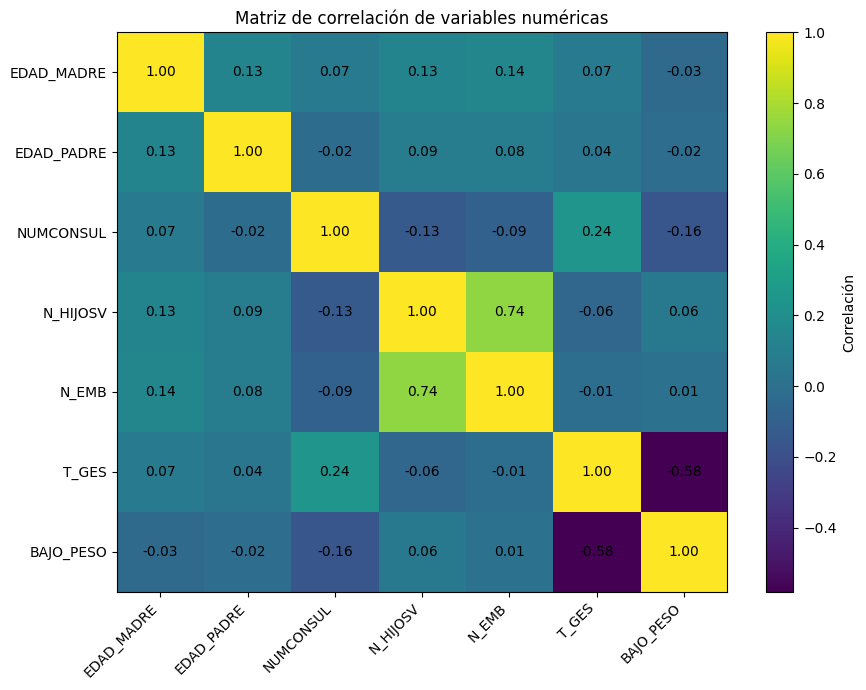

/tmp/ipykernel_1811/1386057137.py:841: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


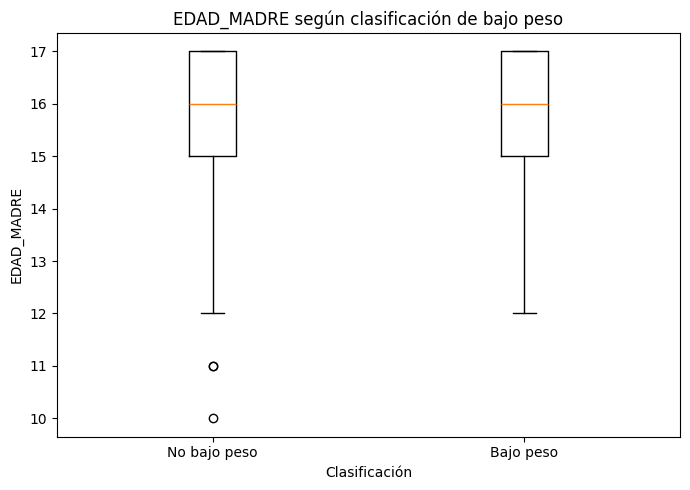

/tmp/ipykernel_1811/1386057137.py:841: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


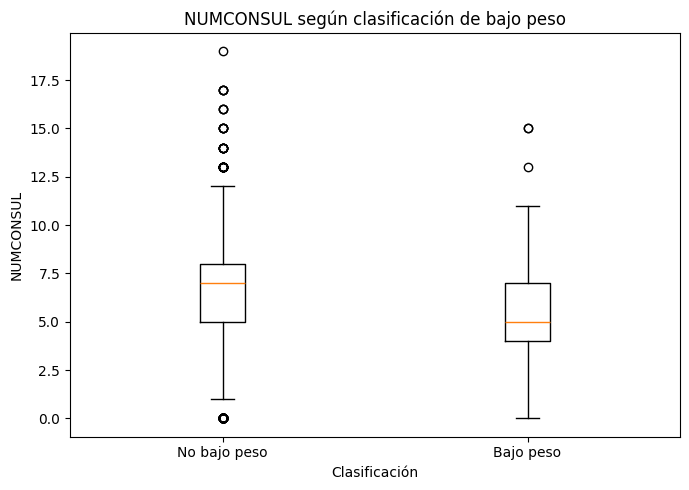

/tmp/ipykernel_1811/1386057137.py:841: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


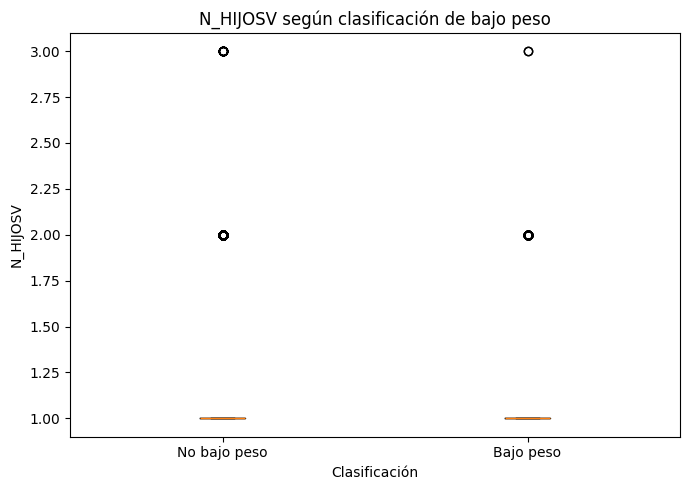

/tmp/ipykernel_1811/1386057137.py:841: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


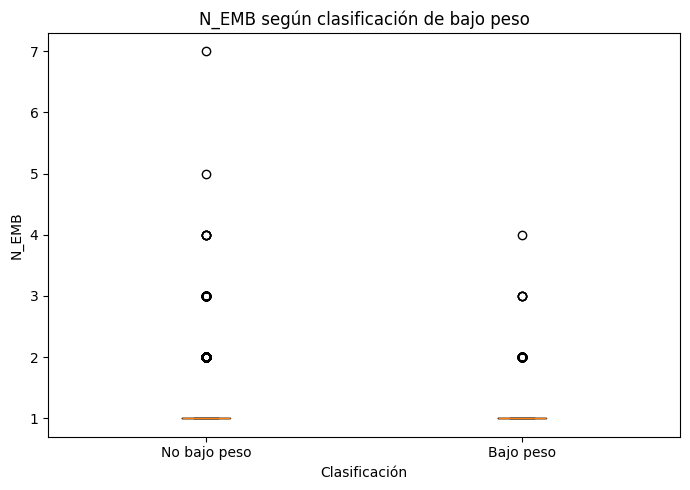

/tmp/ipykernel_1811/1386057137.py:841: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


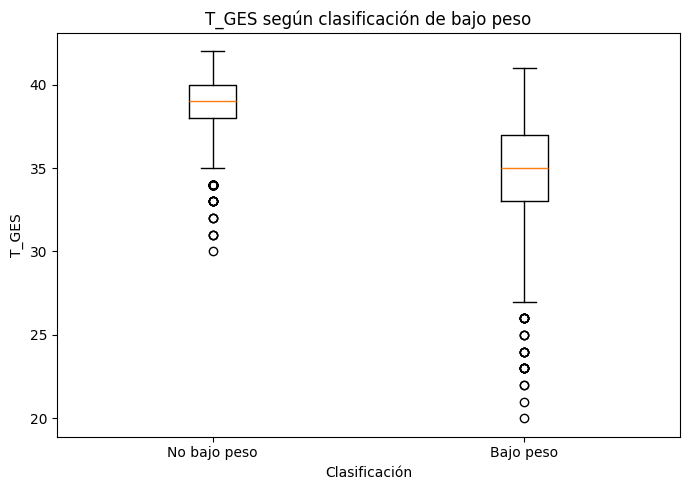


BOXPLOT DE EDAD_PADRE


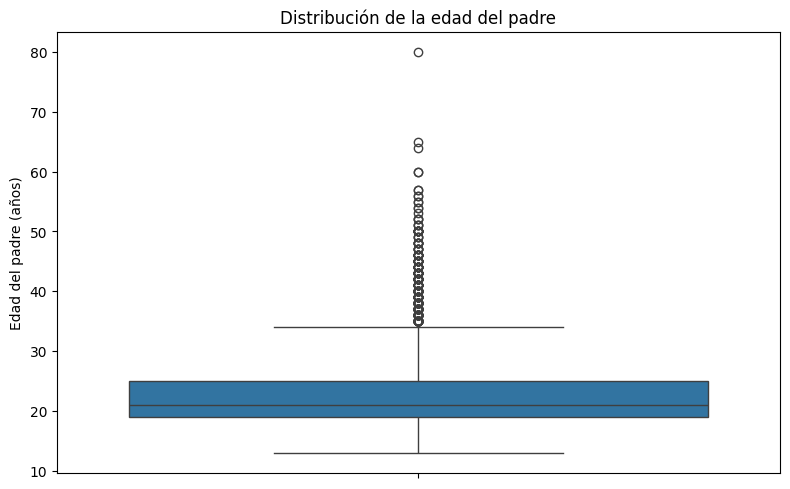

Gráfica guardada en: resultados_etapa_4/Figura_boxplot_EDAD_PADRE.png

RESUMEN DE LA ETAPA 4
Registros analizados: 9502
Variables analizadas: 45
Casos de bajo peso: 762
Casos sin bajo peso: 8740
Variables con algún faltante: 17
Variables numéricas analizadas: 6
Variables categóricas identificadas: 12

Archivos generados:
- 01_valores_faltantes.csv
- 02_distribucion_bajo_peso.csv
- 03_resumen_variables_numericas.csv
- 04_distribucion_edad_madre.csv
- 05_bajo_peso_por_edad_madre.csv
- 06_distribucion_numconsul.csv
- 07_bajo_peso_por_numconsul.csv
- 08_cardinalidad_categoricas.csv
- 09_frecuencia_AREA_RES.csv
- 09_frecuencia_EST_CIVM.csv
- 09_frecuencia_NIV_EDUM.csv
- 09_frecuencia_SEG_SOCIAL.csv
- 10_bajo_peso_por_AREA_RES.csv
- 10_bajo_peso_por_EST_CIVM.csv
- 10_bajo_peso_por_NIV_EDUM.csv
- 10_bajo_peso_por_SEG_SOCIAL.csv
- 11_matriz_correlacion.csv
- 12_cuartiles_variables_numericas.csv
- Figura_1_distribucion_bajo_peso.png
- Figura_2_distribucion_edad_madre.png
- Figura_3_bajo_peso_po

In [3]:
# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

ARCHIVO_ENTRADA = "dataset_analitico_bajo_peso.csv"
CARPETA_SALIDA = "resultados_etapa_4"

os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("=" * 70)
print("ETAPA 4 - ANÁLISIS EXPLORATORIO DE DATOS")
print("=" * 70)


# ------------------------------------------------------------
# 2. CARGA DEL DATASET
# ------------------------------------------------------------

df_eda = pd.read_csv(ARCHIVO_ENTRADA)

print("\nDimensiones del dataset:")
print(f"Registros: {df_eda.shape[0]}")
print(f"Variables: {df_eda.shape[1]}")

print("\nPrimeros registros:")
display(df_eda.head())


# ------------------------------------------------------------
# 3. INFORMACIÓN GENERAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. INFORMACIÓN GENERAL")
print("=" * 70)

print("\nTipos de datos:")
display(
    df_eda.dtypes
    .to_frame("Tipo_dato")
)

print("\nValores faltantes:")
faltantes = pd.DataFrame({
    "Variable": df_eda.columns,
    "Faltantes": df_eda.isna().sum().values
})

faltantes["Porcentaje"] = (
    faltantes["Faltantes"]
    / len(df_eda)
    * 100
)

faltantes = faltantes.sort_values(
    "Porcentaje",
    ascending=False
)

display(faltantes)


# ------------------------------------------------------------
# 4. EXPORTAR TABLA DE FALTANTES
# ------------------------------------------------------------

faltantes.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "01_valores_faltantes.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. DISTRIBUCIÓN DE BAJO_PESO
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("5. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
print("=" * 70)

objetivo = (
    df_eda["BAJO_PESO"]
    .value_counts()
    .sort_index()
    .to_frame("Frecuencia")
)

objetivo["Porcentaje"] = (
    objetivo["Frecuencia"]
    / objetivo["Frecuencia"].sum()
    * 100
)

objetivo["Categoria"] = objetivo.index.map({
    0: "No bajo peso",
    1: "Bajo peso"
})

display(objetivo)

objetivo.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "02_distribucion_bajo_peso.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 6. GRÁFICO - DISTRIBUCIÓN DE BAJO_PESO
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

categorias = ["No bajo peso", "Bajo peso"]
valores = [
    objetivo.loc[0, "Frecuencia"] if 0 in objetivo.index else 0,
    objetivo.loc[1, "Frecuencia"] if 1 in objetivo.index else 0
]

barras = plt.bar(categorias, valores)

plt.title("Distribución de la variable objetivo BAJO_PESO")
plt.xlabel("Clasificación")
plt.ylabel("Número de registros")

for barra, valor in zip(barras, valores):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_1_distribucion_bajo_peso.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. VARIABLES NUMÉRICAS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("7. ANÁLISIS DE VARIABLES NUMÉRICAS")
print("=" * 70)

variables_numericas = [
    "EDAD_MADRE",
    "EDAD_PADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES"
]

variables_numericas = [
    v for v in variables_numericas
    if v in df_eda.columns
]

print("\nVariables numéricas analizadas:")
print(variables_numericas)

resumen_numerico = df_eda[
    variables_numericas
].describe().T

resumen_numerico["Mediana"] = (
    df_eda[variables_numericas].median()
)

resumen_numerico = resumen_numerico[
    [
        "count",
        "mean",
        "Mediana",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

display(resumen_numerico)

resumen_numerico.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "03_resumen_variables_numericas.csv"
    ),
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7.1 ANÁLISIS DE VARIABLES NUMÉRICAS MEDIANTE CUARTILES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("7.1. ANÁLISIS DE VARIABLES NUMÉRICAS MEDIANTE CUARTILES")
print("=" * 70)

variables_cuartiles = [
    "EDAD_MADRE",
    "EDAD_PADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES"
]

resultados_cuartiles = []

for variable in variables_cuartiles:

    if variable in df_eda.columns:

        serie = df_eda[variable].dropna()

        q1 = serie.quantile(0.25)
        mediana = serie.quantile(0.50)
        q3 = serie.quantile(0.75)

        ric = q3 - q1

        limite_inferior = q1 - 1.5 * ric
        limite_superior = q3 + 1.5 * ric

        resultados_cuartiles.append({
            "Variable": variable,
            "Q1": q1,
            "Mediana": mediana,
            "Q3": q3,
            "RIC": ric,
            "Limite_inferior": limite_inferior,
            "Limite_superior": limite_superior
        })

        print(f"\n{variable}")
        print(f"Q1: {q1}")
        print(f"Mediana: {mediana}")
        print(f"Q3: {q3}")
        print(f"RIC: {ric}")
        print(f"Límite inferior: {limite_inferior}")
        print(f"Límite superior: {limite_superior}")

tabla_cuartiles = pd.DataFrame(resultados_cuartiles)

print("\nTabla de cuartiles:")
display(tabla_cuartiles)

tabla_cuartiles.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "12_cuartiles_variables_numericas.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 8. DISTRIBUCIÓN DE EDAD_MADRE
# ------------------------------------------------------------

if "EDAD_MADRE" in df_eda.columns:

    print("\n" + "=" * 70)
    print("8. DISTRIBUCIÓN DE EDAD DE LA MADRE")
    print("=" * 70)

    edad = (
        df_eda["EDAD_MADRE"]
        .value_counts()
        .sort_index()
        .to_frame("Frecuencia")
    )

    edad["Porcentaje"] = (
        edad["Frecuencia"]
        / edad["Frecuencia"].sum()
        * 100
    )

    display(edad)

    edad.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "04_distribucion_edad_madre.csv"
        ),
        encoding="utf-8-sig"
    )

    plt.figure(figsize=(8, 5))

    barras = plt.bar(
        edad.index.astype(str),
        edad["Frecuencia"]
    )

    plt.title("Distribución de la edad de las madres")
    plt.xlabel("Edad de la madre")
    plt.ylabel("Número de registros")

    for barra, valor in zip(barras, edad["Frecuencia"]):
        plt.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height(),
            f"{int(valor):,}",
            ha="center",
            va="bottom",
            fontsize=8
        )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_2_distribucion_edad_madre.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# 9. BAJO PESO SEGÚN EDAD DE LA MADRE
# ------------------------------------------------------------

if "EDAD_MADRE" in df_eda.columns:

    print("\n" + "=" * 70)
    print("9. BAJO PESO SEGÚN EDAD DE LA MADRE")
    print("=" * 70)

    tabla_edad_bpn = pd.crosstab(
        df_eda["EDAD_MADRE"],
        df_eda["BAJO_PESO"]
    )

    tabla_edad_bpn = tabla_edad_bpn.rename(
        columns={
            0: "No_bajo_peso",
            1: "Bajo_peso"
        }
    )

    tabla_edad_bpn["Total"] = tabla_edad_bpn.sum(axis=1)

    tabla_edad_bpn["Porcentaje_bajo_peso"] = (
        tabla_edad_bpn["Bajo_peso"]
        / tabla_edad_bpn["Total"]
        * 100
    )

    display(tabla_edad_bpn)

    tabla_edad_bpn.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "05_bajo_peso_por_edad_madre.csv"
        ),
        encoding="utf-8-sig"
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        tabla_edad_bpn.index,
        tabla_edad_bpn["Porcentaje_bajo_peso"],
        marker="o"
    )

    plt.title(
        "Porcentaje de bajo peso según edad de la madre"
    )

    plt.xlabel("Edad de la madre")
    plt.ylabel("Porcentaje de bajo peso (%)")

    plt.xticks(tabla_edad_bpn.index)

    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_3_bajo_peso_por_edad.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# 10. DISTRIBUCIÓN DE NUMCONSUL
# ------------------------------------------------------------

if "NUMCONSUL" in df_eda.columns:

    print("\n" + "=" * 70)
    print("10. DISTRIBUCIÓN DE CONSULTAS PRENATALES")
    print("=" * 70)

    consultas = (
        df_eda["NUMCONSUL"]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("Frecuencia")
    )

    consultas["Porcentaje"] = (
        consultas["Frecuencia"]
        / len(df_eda)
        * 100
    )

    display(consultas)

    consultas.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "06_distribucion_numconsul.csv"
        ),
        encoding="utf-8-sig"
    )

    datos_consultas = (
        df_eda["NUMCONSUL"]
        .dropna()
    )

    plt.figure(figsize=(8, 5))

    plt.hist(
        datos_consultas,
        bins=range(
            int(datos_consultas.min()),
            int(datos_consultas.max()) + 2
        ),
        edgecolor="black"
    )

    plt.title(
        "Distribución del número de consultas prenatales"
    )

    plt.xlabel("Número de consultas")
    plt.ylabel("Número de registros")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_4_distribucion_consultas.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# 11. BAJO PESO SEGÚN NUMCONSUL
# ------------------------------------------------------------

if "NUMCONSUL" in df_eda.columns:

    print("\n" + "=" * 70)
    print("11. BAJO PESO SEGÚN NÚMERO DE CONSULTAS")
    print("=" * 70)

    tabla_consultas_bpn = pd.crosstab(
        df_eda["NUMCONSUL"],
        df_eda["BAJO_PESO"]
    )

    tabla_consultas_bpn = tabla_consultas_bpn.rename(
        columns={
            0: "No_bajo_peso",
            1: "Bajo_peso"
        }
    )

    tabla_consultas_bpn["Total"] = (
        tabla_consultas_bpn.sum(axis=1)
    )

    tabla_consultas_bpn["Porcentaje_bajo_peso"] = (
        tabla_consultas_bpn["Bajo_peso"]
        / tabla_consultas_bpn["Total"]
        * 100
    )

    display(tabla_consultas_bpn)

    tabla_consultas_bpn.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "07_bajo_peso_por_numconsul.csv"
        ),
        encoding="utf-8-sig"
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        tabla_consultas_bpn.index,
        tabla_consultas_bpn["Porcentaje_bajo_peso"],
        marker="o"
    )

    plt.title(
        "Porcentaje de bajo peso según número de consultas prenatales"
    )

    plt.xlabel("Número de consultas")
    plt.ylabel("Porcentaje de bajo peso (%)")

    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_5_bajo_peso_por_consultas.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# 12. VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("12. VARIABLES CATEGÓRICAS")
print("=" * 70)

variables_categoricas = df_eda.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables categóricas:")
print(variables_categoricas)


# ------------------------------------------------------------
# 13. CARDINALIDAD DE VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

cardinalidad = []

for variable in variables_categoricas:

    cardinalidad.append({
        "Variable": variable,
        "Categorias_unicas": df_eda[variable].nunique(
            dropna=True
        ),
        "Faltantes": df_eda[variable].isna().sum()
    })

cardinalidad = pd.DataFrame(cardinalidad)

cardinalidad = cardinalidad.sort_values(
    "Categorias_unicas",
    ascending=False
)

display(cardinalidad)

cardinalidad.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "08_cardinalidad_categoricas.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 14. ANÁLISIS DE VARIABLES CATEGÓRICAS SELECCIONADAS
# ------------------------------------------------------------

variables_categoricas_interes = [
    "EST_CIVM",
    "NIV_EDUM",
    "AREA_RES",
    "SEG_SOCIAL"
]

variables_categoricas_interes = [
    v for v in variables_categoricas_interes
    if v in df_eda.columns
]


for variable in variables_categoricas_interes:

    print("\n" + "=" * 70)
    print(f"ANÁLISIS DE {variable}")
    print("=" * 70)

    tabla = (
        df_eda[variable]
        .value_counts(dropna=False)
        .to_frame("Frecuencia")
    )

    tabla["Porcentaje"] = (
        tabla["Frecuencia"]
        / len(df_eda)
        * 100
    )

    display(tabla)

    nombre_archivo = (
        f"09_frecuencia_{variable}.csv"
    )

    tabla.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            nombre_archivo
        ),
        encoding="utf-8-sig"
    )


# ------------------------------------------------------------
# 15. BAJO PESO SEGÚN VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

for variable in variables_categoricas_interes:

    print("\n" + "=" * 70)
    print(f"BAJO PESO SEGÚN {variable}")
    print("=" * 70)

    tabla = pd.crosstab(
        df_eda[variable],
        df_eda["BAJO_PESO"]
    )

    tabla = tabla.rename(
        columns={
            0: "No_bajo_peso",
            1: "Bajo_peso"
        }
    )

    tabla["Total"] = tabla.sum(axis=1)

    tabla["Porcentaje_bajo_peso"] = (
        tabla["Bajo_peso"]
        / tabla["Total"]
        * 100
    )

    display(tabla)

    nombre_archivo = (
        f"10_bajo_peso_por_{variable}.csv"
    )

    tabla.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            nombre_archivo
        ),
        encoding="utf-8-sig"
    )


# ------------------------------------------------------------
# 16. MATRIZ DE CORRELACIÓN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("16. CORRELACIÓN ENTRE VARIABLES NUMÉRICAS")
print("=" * 70)

variables_corr = [
    "EDAD_MADRE",
    "EDAD_PADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES",
    "BAJO_PESO"
]

variables_corr = [
    v for v in variables_corr
    if v in df_eda.columns
]

correlacion = df_eda[
    variables_corr
].corr(numeric_only=True)

display(correlacion)

correlacion.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "11_matriz_correlacion.csv"
    ),
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 17. GRÁFICO DE CORRELACIÓN
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.imshow(
    correlacion,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(label="Correlación")

plt.xticks(
    range(len(correlacion.columns)),
    correlacion.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlacion.index)),
    correlacion.index
)

plt.title(
    "Matriz de correlación de variables numéricas"
)

# Mostrar valores dentro de la matriz
for i in range(len(correlacion.index)):
    for j in range(len(correlacion.columns)):

        valor = correlacion.iloc[i, j]

        if not pd.isna(valor):

            plt.text(
                j,
                i,
                f"{valor:.2f}",
                ha="center",
                va="center"
            )

plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_6_matriz_correlacion.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 18. BOXPLOTS DE VARIABLES NUMÉRICAS SEGÚN BAJO_PESO
# ------------------------------------------------------------

variables_boxplot = [
    "EDAD_MADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES"
]

variables_boxplot = [
    v for v in variables_boxplot
    if v in df_eda.columns
]

for variable in variables_boxplot:

    datos_0 = df_eda.loc[
        df_eda["BAJO_PESO"] == 0,
        variable
    ].dropna()

    datos_1 = df_eda.loc[
        df_eda["BAJO_PESO"] == 1,
        variable
    ].dropna()

    if len(datos_0) == 0 or len(datos_1) == 0:
        continue

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        [datos_0, datos_1],
        labels=[
            "No bajo peso",
            "Bajo peso"
        ]
    )

    plt.title(
        f"{variable} según clasificación de bajo peso"
    )

    plt.xlabel("Clasificación")
    plt.ylabel(variable)

    plt.tight_layout()

    nombre = (
        f"Figura_boxplot_{variable}.png"
    )

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            nombre
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# BOXPLOT DE EDAD_PADRE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BOXPLOT DE EDAD_PADRE")
print("=" * 70)

import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df_eda["EDAD_PADRE"].dropna()
)

plt.title("Distribución de la edad del padre")
plt.ylabel("Edad del padre (años)")
plt.xlabel("")

plt.tight_layout()

ruta_boxplot_padre = os.path.join(
    CARPETA_SALIDA,
    "Figura_boxplot_EDAD_PADRE.png"
)

plt.savefig(
    ruta_boxplot_padre,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Gráfica guardada en: {ruta_boxplot_padre}"
)

# ------------------------------------------------------------
# 19. RESUMEN FINAL DE LA ETAPA
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMEN DE LA ETAPA 4")
print("=" * 70)

print(f"Registros analizados: {len(df_eda)}")
print(f"Variables analizadas: {df_eda.shape[1]}")

print(
    f"Casos de bajo peso: "
    f"{(df_eda['BAJO_PESO'] == 1).sum()}"
)

print(
    f"Casos sin bajo peso: "
    f"{(df_eda['BAJO_PESO'] == 0).sum()}"
)

print(
    f"Variables con algún faltante: "
    f"{(df_eda.isna().sum() > 0).sum()}"
)

print(
    f"Variables numéricas analizadas: "
    f"{len(variables_numericas)}"
)

print(
    f"Variables categóricas identificadas: "
    f"{len(variables_categoricas)}"
)

print("\nArchivos generados:")

for archivo in sorted(os.listdir(CARPETA_SALIDA)):
    print("-", archivo)

print("\nETAPA 4 FINALIZADA.")

In [4]:
#!zip -r carpeta_comprimida.zip /content/resultados_etapa_4
#from google.colab import files
#files.download('carpeta_comprimida.zip')


SENSIBILIDAD DE EDAD MATERNA A VALORES ATÍPICOS
Q1=15.00; Q3=17.00; RIC=2.00
Límite inferior=12.00; límite superior=20.00
Registros atípicos identificados: 3


,EDAD_MADRE,BAJO_PESO,Frecuencia
0,10,0,1
1,11,0,2


Registros completos: 9502
Registros en vista de sensibilidad: 9499
La vista filtrada se usa solo para esta comparación exploratoria; df_eda y la base preparada permanecen intactos.


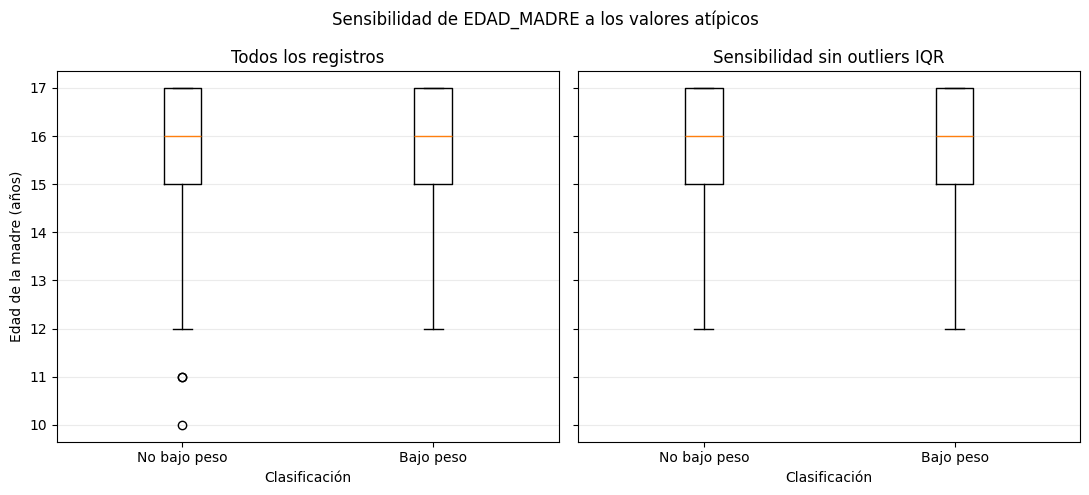

Figura guardada en: resultados_etapa_4/Figura_7_sensibilidad_outliers_edad_madre.png
TABLA DE CONTINGENCIA: BAJO PESO POR GRUPO DE CONSULTAS


BAJO_PESO,No_bajo_peso,Bajo_peso,Total,Porcentaje_bajo_peso
GRUPO_CONSULTAS,,,,
0,81,32,113,28.318584
1-4,1395,255,1650,15.454545
5-8,5794,433,6227,6.953589
9 o más,1404,41,1445,2.837370


Chi-cuadrado=247.6459; gl=3; p=2.1134e-53; V de Cramér=0.1620
Las frecuencias esperadas son >=5 en todas las celdas de esta tabla agrupada.
TABLA DE CONTINGENCIA POR VALOR EXACTO DE NUMCONSUL


BAJO_PESO,No_bajo_peso,Bajo_peso
NUMCONSUL,,
0.0,81,32
1.0,149,28
2.0,213,53
3.0,387,67
4.0,646,107
5.0,1002,112
6.0,1216,107
7.0,2159,138
8.0,1417,76


ANOVA DE WELCH Y CONTRASTE KRUSKAL-WALLIS POR CLASIFICACIÓN DE BAJO PESO


,Variable_respuesta,n_no_bajo_peso,media_no_bajo_peso,n_bajo_peso,media_bajo_peso,F_Welch,gl1,gl2,p_Welch,eta_cuadrado,H_Kruskal,p_Kruskal
0,NUMCONSUL,8674,6.516025,761,5.182654,214.085674,1,874.066736,1.586699e-43,0.025889,226.676354,3.163711e-51
1,T_GES,8731,38.914557,761,34.629435,1043.201871,1,777.410886,8.400306e-146,0.337934,1366.549424,3.902772e-299


Interpretación: se comparan medias entre grupos; los resultados son descriptivos/inferenciales y no indican causalidad.
ASOCIACIÓN NO LINEAL: INFORMACIÓN MUTUA NORMALIZADA


,Variable,Comparada_con,NMI,IC95_bootstrap_inferior,IC95_bootstrap_superior,p_permutacion,n,bootstrap_replicas,permutaciones
0,NUMCONSUL,BAJO_PESO,0.017958,0.015274,0.023481,0.000999,9435,500,1000
1,T_GES,BAJO_PESO,0.169847,0.158448,0.184466,0.000999,9492,500,1000


NMI resume dependencia, no su dirección ni causalidad. El intervalo es bootstrap percentil del 95 %.
Ampliación de la Etapa 4 finalizada.


In [5]:
# ------------------------------------------------------------
# ETAPA 4 - SENSIBILIDAD DE OUTLIERS Y ANÁLISIS INFERENCIAL
# ------------------------------------------------------------

import math
import numpy as np
from scipy import stats

# Validar las columnas requeridas sin modificar df_eda ni el archivo de Etapa 3.
columnas_requeridas = {"EDAD_MADRE", "BAJO_PESO", "NUMCONSUL", "T_GES"}
columnas_faltantes = columnas_requeridas.difference(df_eda.columns)
if columnas_faltantes:
    raise ValueError(f"Faltan columnas requeridas para la Etapa 4: {sorted(columnas_faltantes)}")

# 1. Sensibilidad para los outliers de EDAD_MADRE.
# El criterio IQR detecta casos estadísticamente atípicos; no prueba error de captura.
edades_validas = df_eda["EDAD_MADRE"].dropna()
q1_edad = edades_validas.quantile(0.25)
q3_edad = edades_validas.quantile(0.75)
ric_edad = q3_edad - q1_edad
limite_inf_edad = q1_edad - 1.5 * ric_edad
limite_sup_edad = q3_edad + 1.5 * ric_edad
mascara_outlier_edad = (
    df_eda["EDAD_MADRE"].notna()
    & ((df_eda["EDAD_MADRE"] < limite_inf_edad)
       | (df_eda["EDAD_MADRE"] > limite_sup_edad))
)
outliers_edad = df_eda.loc[mascara_outlier_edad].copy()
df_eda_sin_outliers_edad = df_eda.loc[~mascara_outlier_edad].copy()

print("SENSIBILIDAD DE EDAD MATERNA A VALORES ATÍPICOS")
print(f"Q1={q1_edad:.2f}; Q3={q3_edad:.2f}; RIC={ric_edad:.2f}")
print(f"Límite inferior={limite_inf_edad:.2f}; límite superior={limite_sup_edad:.2f}")
print(f"Registros atípicos identificados: {len(outliers_edad)}")
if len(outliers_edad):
    display(
        outliers_edad.groupby(["EDAD_MADRE", "BAJO_PESO"], dropna=False)
        .size().rename("Frecuencia").reset_index()
    )
print(f"Registros completos: {len(df_eda)}")
print(f"Registros en vista de sensibilidad: {len(df_eda_sin_outliers_edad)}")
print("La vista filtrada se usa solo para esta comparación exploratoria; df_eda y la base preparada permanecen intactos.")

# Comparar la edad materna por grupo de bajo peso con y sin los casos IQR.
fig, ejes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for eje, datos, titulo in [
    (ejes[0], df_eda, "Todos los registros"),
    (ejes[1], df_eda_sin_outliers_edad, "Sensibilidad sin outliers IQR")
]:
    grupos_edad = [
        datos.loc[datos["BAJO_PESO"] == clase, "EDAD_MADRE"].dropna()
        for clase in [0, 1]
    ]
    eje.boxplot(grupos_edad, tick_labels=["No bajo peso", "Bajo peso"])
    eje.set_title(titulo)
    eje.set_xlabel("Clasificación")
    eje.grid(axis="y", alpha=0.25)
ejes[0].set_ylabel("Edad de la madre (años)")
fig.suptitle("Sensibilidad de EDAD_MADRE a los valores atípicos")
fig.tight_layout()
ruta_figura_sensibilidad = os.path.join(CARPETA_SALIDA, "Figura_7_sensibilidad_outliers_edad_madre.png")
fig.savefig(ruta_figura_sensibilidad, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {ruta_figura_sensibilidad}")

# 2. Tabla de contingencia: bajo peso por número de consultas.
# Se conserva NUMCONSUL original; estos intervalos solo se usan para resumir la tabla.
limites_consultas = [-0.001, 0, 4, 8, np.inf]
etiquetas_consultas = ["0", "1-4", "5-8", "9 o más"]
datos_contingencia = df_eda[["NUMCONSUL", "BAJO_PESO"]].dropna().copy()
datos_contingencia["GRUPO_CONSULTAS"] = pd.cut(
    datos_contingencia["NUMCONSUL"],
    bins=limites_consultas,
    labels=etiquetas_consultas,
    include_lowest=True
)
tabla_contingencia = pd.crosstab(
    datos_contingencia["GRUPO_CONSULTAS"],
    datos_contingencia["BAJO_PESO"],
    dropna=False
).reindex(etiquetas_consultas, fill_value=0)
tabla_contingencia = tabla_contingencia.rename(
    columns={0: "No_bajo_peso", 1: "Bajo_peso"}
)
tabla_contingencia["Total"] = tabla_contingencia.sum(axis=1)
tabla_contingencia["Porcentaje_bajo_peso"] = (
    tabla_contingencia["Bajo_peso"] / tabla_contingencia["Total"].replace(0, np.nan) * 100
)
print("TABLA DE CONTINGENCIA: BAJO PESO POR GRUPO DE CONSULTAS")
display(tabla_contingencia)
tabla_contingencia.to_csv(
    os.path.join(CARPETA_SALIDA, "13_contingencia_bajo_peso_por_consultas.csv"),
    encoding="utf-8-sig"
)

observadas = tabla_contingencia[["No_bajo_peso", "Bajo_peso"]].to_numpy()
chi2, p_chi2, gl_chi2, esperadas = stats.chi2_contingency(observadas, correction=False)
n_contingencia = observadas.sum()
cramer_v = math.sqrt(chi2 / (n_contingencia * min(observadas.shape[0] - 1, observadas.shape[1] - 1)))
print(f"Chi-cuadrado={chi2:.4f}; gl={gl_chi2}; p={p_chi2:.6g}; V de Cramér={cramer_v:.4f}")
if (esperadas < 5).any():
    print("ADVERTENCIA: hay frecuencias esperadas menores de 5; interpretar el p-valor asintótico con cautela.")
else:
    print("Las frecuencias esperadas son >=5 en todas las celdas de esta tabla agrupada.")

# También conservar la tabla por cada número exacto para inspeccionar categorías escasas.
tabla_consultas_exactas = pd.crosstab(
    datos_contingencia["NUMCONSUL"], datos_contingencia["BAJO_PESO"]
).rename(columns={0: "No_bajo_peso", 1: "Bajo_peso"})
print("TABLA DE CONTINGENCIA POR VALOR EXACTO DE NUMCONSUL")
display(tabla_consultas_exactas)
tabla_consultas_exactas.to_csv(
    os.path.join(CARPETA_SALIDA, "14_contingencia_consultas_valor_exacto.csv"),
    encoding="utf-8-sig"
)

# 3. ANOVA de Welch: comparación de NUMCONSUL y T_GES entre clases de BAJO_PESO.
# Welch no exige igualdad de varianzas; Kruskal-Wallis se añade como contraste robusto.
def anova_welch(grupos):
    grupos = [np.asarray(g, dtype=float) for g in grupos]
    grupos = [g[np.isfinite(g)] for g in grupos]
    if len(grupos) < 2 or any(len(g) < 2 for g in grupos):
        return np.nan, np.nan, np.nan, np.nan
    k = len(grupos)
    n = np.array([len(g) for g in grupos], dtype=float)
    medias = np.array([np.mean(g) for g in grupos], dtype=float)
    varianzas = np.array([np.var(g, ddof=1) for g in grupos], dtype=float)
    if np.any(varianzas <= 0):
        return np.nan, np.nan, np.nan, np.nan
    pesos = n / varianzas
    suma_pesos = pesos.sum()
    media_ponderada = np.sum(pesos * medias) / suma_pesos
    termino = np.sum((1 - pesos / suma_pesos) ** 2 / (n - 1))
    f_estadistico = (
        np.sum(pesos * (medias - media_ponderada) ** 2) / (k - 1)
    ) / (1 + (2 * (k - 2) / (k**2 - 1)) * termino)
    gl1 = k - 1
    gl2 = (k**2 - 1) / (3 * termino) if termino > 0 else np.inf
    p_valor = stats.f.sf(f_estadistico, gl1, gl2)
    return f_estadistico, gl1, gl2, p_valor

filas_anova = []
for variable in ["NUMCONSUL", "T_GES"]:
    datos_anova = df_eda[[variable, "BAJO_PESO"]].dropna()
    grupos = [
        datos_anova.loc[datos_anova["BAJO_PESO"] == clase, variable].to_numpy(dtype=float)
        for clase in [0, 1]
    ]
    f_welch, gl1, gl2, p_welch = anova_welch(grupos)
    h_kw, p_kw = stats.kruskal(*grupos)
    n0, n1 = len(grupos[0]), len(grupos[1])
    media0, media1 = np.mean(grupos[0]), np.mean(grupos[1])
    ss_total = np.sum((datos_anova[variable] - datos_anova[variable].mean()) ** 2)
    ss_entre = sum(len(g) * (np.mean(g) - datos_anova[variable].mean()) ** 2 for g in grupos)
    eta2 = ss_entre / ss_total if ss_total > 0 else np.nan
    filas_anova.append({
        "Variable_respuesta": variable,
        "n_no_bajo_peso": n0,
        "media_no_bajo_peso": media0,
        "n_bajo_peso": n1,
        "media_bajo_peso": media1,
        "F_Welch": f_welch,
        "gl1": gl1,
        "gl2": gl2,
        "p_Welch": p_welch,
        "eta_cuadrado": eta2,
        "H_Kruskal": h_kw,
        "p_Kruskal": p_kw
    })
tabla_anova = pd.DataFrame(filas_anova)
print("ANOVA DE WELCH Y CONTRASTE KRUSKAL-WALLIS POR CLASIFICACIÓN DE BAJO PESO")
display(tabla_anova)
tabla_anova.to_csv(
    os.path.join(CARPETA_SALIDA, "15_anova_consultas_y_gestacion_por_bajo_peso.csv"),
    index=False,
    encoding="utf-8-sig"
)
print("Interpretación: se comparan medias entre grupos; los resultados son descriptivos/inferenciales y no indican causalidad.")

# 4. Asociación no lineal con Información Mutua Normalizada (NMI).
# Intervalos por bootstrap de registros y p-valor por permutación de BAJO_PESO.
def nmi_categorica(x, y):
    x_codes = pd.factorize(pd.Series(x), sort=True)[0]
    y_codes = pd.factorize(pd.Series(y), sort=True)[0]
    validos = (x_codes >= 0) & (y_codes >= 0)
    x_codes, y_codes = x_codes[validos], y_codes[validos]
    if len(x_codes) == 0:
        return np.nan
    nx, ny = int(x_codes.max()) + 1, int(y_codes.max()) + 1
    conjunta = np.bincount(x_codes * ny + y_codes, minlength=nx * ny).reshape(nx, ny).astype(float)
    pxy = conjunta / conjunta.sum()
    px, py = pxy.sum(axis=1), pxy.sum(axis=0)
    hx = -np.sum(px[px > 0] * np.log(px[px > 0]))
    hy = -np.sum(py[py > 0] * np.log(py[py > 0]))
    if hx == 0 or hy == 0:
        return 0.0
    denominador = px[:, None] * py[None, :]
    mascara = pxy > 0
    mi = np.sum(pxy[mascara] * np.log(pxy[mascara] / denominador[mascara]))
    return float(mi / math.sqrt(hx * hy))

rng_nmi = np.random.default_rng(20261009)
filas_nmi = []
for variable in ["NUMCONSUL", "T_GES"]:
    datos_nmi = df_eda[[variable, "BAJO_PESO"]].dropna()
    x = datos_nmi[variable].to_numpy()
    y = datos_nmi["BAJO_PESO"].to_numpy()
    nmi_observada = nmi_categorica(x, y)
    n_bootstrap, n_permutaciones = 500, 1000
    valores_bootstrap = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        indices = rng_nmi.integers(0, len(y), size=len(y))
        valores_bootstrap[i] = nmi_categorica(x[indices], y[indices])
    ci_inf, ci_sup = np.nanpercentile(valores_bootstrap, [2.5, 97.5])
    valores_perm = np.empty(n_permutaciones)
    for i in range(n_permutaciones):
        valores_perm[i] = nmi_categorica(x, rng_nmi.permutation(y))
    p_permutacion = (1 + np.sum(valores_perm >= nmi_observada)) / (n_permutaciones + 1)
    filas_nmi.append({
        "Variable": variable,
        "Comparada_con": "BAJO_PESO",
        "NMI": nmi_observada,
        "IC95_bootstrap_inferior": ci_inf,
        "IC95_bootstrap_superior": ci_sup,
        "p_permutacion": p_permutacion,
        "n": len(y),
        "bootstrap_replicas": n_bootstrap,
        "permutaciones": n_permutaciones
    })
tabla_nmi = pd.DataFrame(filas_nmi)
print("ASOCIACIÓN NO LINEAL: INFORMACIÓN MUTUA NORMALIZADA")
display(tabla_nmi)
tabla_nmi.to_csv(
    os.path.join(CARPETA_SALIDA, "16_asociacion_no_lineal_nmi_bajo_peso.csv"),
    index=False,
    encoding="utf-8-sig"
)
print("NMI resume dependencia, no su dirección ni causalidad. El intervalo es bootstrap percentil del 95 %.")
print("Ampliación de la Etapa 4 finalizada.")

## ETAPA 5 - MODELADO
Metodología: CRISP-DM

**Objetivo:**
Entrenar y validar los modelos de clasificación (Regresión Logística, Árbol de Decisión y Random Forest) sobre el dataset analítico construido en la Etapa 3.

ETAPA 5 - MODELADO

Semilla aleatoria: 42
Proporción del conjunto de prueba: 0.3
Folds de validación cruzada: 5

Dimensiones del dataset analítico:
Registros: 9502
Variables: 45

Distribución de la variable objetivo:


,Frecuencia,Porcentaje
BAJO_PESO,,
0,8740,91.980636
1,762,8.019364



3. CONJUNTO DE PREDICTORES SELECCIONADO

Variables numéricas (4):
['EDAD_MADRE', 'EDAD_PADRE', 'N_HIJOSV', 'N_EMB']

Variables categóricas (7):
['EST_CIVM', 'NIV_EDUM', 'NIV_EDUP', 'AREA_RES', 'SEG_SOCIAL', 'IDPUEBLOIN', 'MUL_PARTO']

Total de predictores: 11

4. JUSTIFICACIÓN DE LAS VARIABLES EXCLUIDAS DEL MODELADO

- PESO_NAC / PESO_G:
  Excluidas en la Etapa 3. Son la base de la variable objetivo.

- TALLA_NAC / APGAR1 / APGAR2 / TIPO_PARTO:
  Excluidas en la Etapa 3. Resultados del nacimiento.

- SIT_PARTO:
  Sitio del parto. Se conoce en el momento del parto y queda fuera del momento de predicción definido.

- ATEN_PAR:
  Personal que atendió el parto. Se conoce en el momento del parto.

- OTRO_SIT / OTRPARATX / COD_INSP / NOM_PUEB / VEREDAMAD:
  Proporción de valores faltantes superior al 70 %.

- BARRMADRE:
  Alta cardinalidad (más de 1.500 categorías) y 38 % de faltantes.

- CODPRES / CODPTORE:
  Constantes en la base analizada. No aportan variación.

- COD_MUNIC / CODMUNRE / 

,Variable,Tipo,Justificacion,Faltantes_pct
0,EDAD_MADRE,Numérica,Variable materna central del estudio. Disponib...,0.00
1,EDAD_PADRE,Numérica,Variable paterna candidata. Códigos 99 y 999 t...,2.78
2,N_HIJOSV,Numérica,Antecedente reproductivo disponible antes del ...,0.00
3,N_EMB,Numérica,Antecedente reproductivo disponible antes del ...,0.00
4,EST_CIVM,Categórica,Condición sociodemográfica materna.,0.00
5,NIV_EDUM,Categórica,Nivel educativo de la madre. Código 99 tratado...,1.46
6,NIV_EDUP,Categórica,Nivel educativo del padre.,0.00
7,AREA_RES,Categórica,Área de residencia. Dimensión territorial con ...,0.00
8,SEG_SOCIAL,Categórica,Régimen de seguridad social. Condición de acce...,0.00
9,IDPUEBLOIN,Categórica,Pertenencia étnica declarada.,0.00



5. MATRIZ DE PREDICTORES

Dimensiones de X: (9502, 11)
Dimensiones de y: (9502,)
Casos positivos (bajo peso): 762
Casos negativos: 8740

6. PARTICIÓN DE LOS DATOS


,Conjunto,Registros,Bajo_peso,No_bajo_peso,Porcentaje_bajo_peso
0,Entrenamiento,6651,533,6118,8.01
1,Prueba,2851,229,2622,8.03
2,Total,9502,762,8740,8.02



7. PREPROCESAMIENTO DEFINIDO

Variables numéricas: imputación por mediana y estandarización.
Variables categóricas: imputación por moda y codificación One-Hot.
Categorías con menos de 20 registros agrupadas como infrecuentes.
El ajuste se realiza solo con el conjunto de entrenamiento.

NIV_EDUP: el código 99 se conserva como categoría de 'sin información' (1.731 registros).

9. BÚSQUEDA DE HIPERPARÁMETROS

Ajustando: Regresión Logística
Mejores parámetros: {'modelo__C': 0.01}
ROC-AUC en validación cruzada: 0.5589

Ajustando: Árbol de Decisión
Mejores parámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 50}
ROC-AUC en validación cruzada: 0.5685

Ajustando: Random Forest
Mejores parámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1}
ROC-AUC en validación cruzada: 0.5629

Resumen de la búsqueda de hiperparámetros:


,Modelo,Mejores_parametros,ROC_AUC_validacion_cruzada
0,Regresión Logística,{'modelo__C': 0.01},0.5589
1,Árbol de Decisión,"{'modelo__max_depth': 8, 'modelo__min_samples_...",0.5685
2,Random Forest,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.5629



10. VALIDACIÓN CRUZADA ESTRATIFICADA

Regresión Logística
  ROC-AUC: 0.5589 (± 0.0232)
  Recall:  0.4146 (± 0.0213)
  F1:      0.1628 (± 0.0119)

Árbol de Decisión
  ROC-AUC: 0.5685 (± 0.0204)
  Recall:  0.4352 (± 0.1103)
  F1:      0.1634 (± 0.0046)

Random Forest
  ROC-AUC: 0.5629 (± 0.0152)
  Recall:  0.1483 (± 0.0327)
  F1:      0.1628 (± 0.0366)

Tabla de validación cruzada:


,Modelo,roc_auc_media,roc_auc_desv,average_precision_media,average_precision_desv,recall_media,recall_desv,precision_media,precision_desv,f1_media,f1_desv,accuracy_media,accuracy_desv
0,Regresión Logística,0.5589,0.0232,0.1842,0.0154,0.4146,0.0213,0.1013,0.0085,0.1628,0.0119,0.6570,0.0215
1,Árbol de Decisión,0.5685,0.0204,0.1745,0.0199,0.4352,0.1103,0.1025,0.0052,0.1634,0.0046,0.6452,0.0804
2,Random Forest,0.5629,0.0152,0.1621,0.0101,0.1483,0.0327,0.1807,0.0422,0.1628,0.0366,0.8775,0.0073


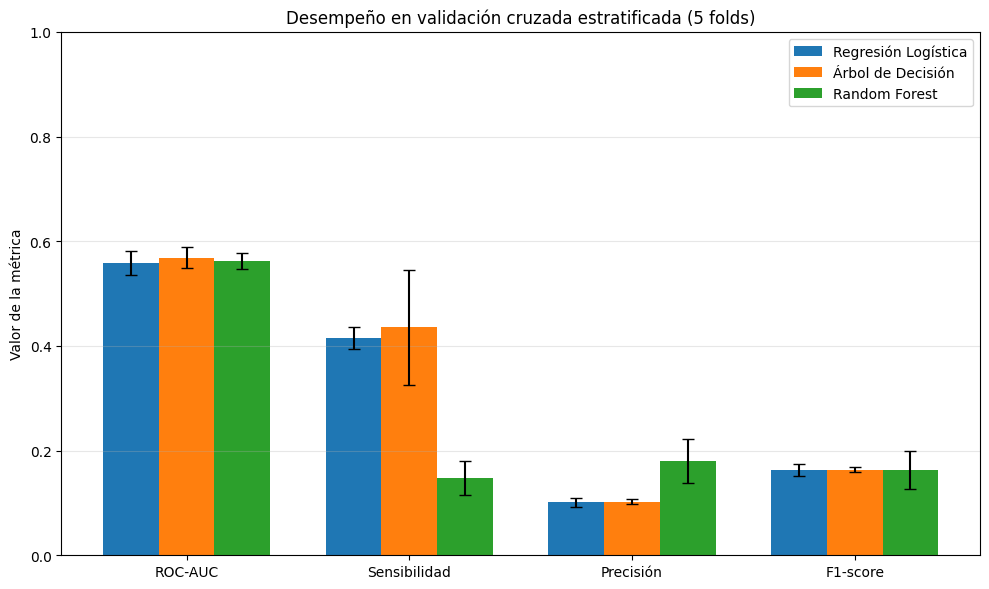


RESUMEN DE LA ETAPA 5

Registros utilizados: 9502
Predictores utilizados: 11
Registros de entrenamiento: 6651
Registros de prueba: 2851
Modelos entrenados: 3

Mejor ROC-AUC en validación cruzada: Árbol de Decisión

Archivos generados:
- 17_conjunto_predictores.csv
- 18_particion_entrenamiento_prueba.csv
- 19_hiperparametros_seleccionados.csv
- 20_validacion_cruzada_modelos.csv
- 21_validacion_cruzada_detalle_folds.csv
- Figura_12_validacion_cruzada_modelos.png

ETAPA 5 FINALIZADA.
Los objetos modelos_entrenados, X_train, X_test, y_train y y_test quedan disponibles para la Etapa 6.


In [10]:
# ------------------------------------------------------------
# ETAPA 5 - MODELADO
# ------------------------------------------------------------
#
# Modelos: Regresión Logística, Árbol de Decisión y Random Forest.
#
# Momento de predicción definido para el proyecto:
# final del embarazo, con la información disponible en el control
# prenatal y en la valoración ecográfica. Bajo esta definición se
# admiten T_GES, SEXO y MUL_PARTO como predictores, y se mantienen
# excluidas las variables generadas durante o después del parto.
#
# ------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

ARCHIVO_ENTRADA = "dataset_analitico_bajo_peso.csv"
CARPETA_SALIDA = "resultados_etapa_5"

SEMILLA = 42
PROPORCION_PRUEBA = 0.30
NUMERO_FOLDS = 5

os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("=" * 70)
print("ETAPA 5 - MODELADO")
print("=" * 70)

print(f"\nSemilla aleatoria: {SEMILLA}")
print(f"Proporción del conjunto de prueba: {PROPORCION_PRUEBA}")
print(f"Folds de validación cruzada: {NUMERO_FOLDS}")


# ------------------------------------------------------------
# 2. CARGA DEL DATASET ANALÍTICO
# ------------------------------------------------------------

df_modelado = pd.read_csv(ARCHIVO_ENTRADA)

print("\nDimensiones del dataset analítico:")
print(f"Registros: {df_modelado.shape[0]}")
print(f"Variables: {df_modelado.shape[1]}")

print("\nDistribución de la variable objetivo:")

distribucion_objetivo = (
    df_modelado["BAJO_PESO"]
    .value_counts()
    .sort_index()
    .to_frame("Frecuencia")
)

distribucion_objetivo["Porcentaje"] = (
    distribucion_objetivo["Frecuencia"]
    / distribucion_objetivo["Frecuencia"].sum()
    * 100
)

display(distribucion_objetivo)


# ------------------------------------------------------------
# 3. DEFINICIÓN DEL CONJUNTO DE PREDICTORES
# ------------------------------------------------------------
#
# El conjunto se construye a partir del diccionario de variables
# candidatas de la Etapa 2 y de los hallazgos de la Etapa 4.

variables_numericas = [
    "EDAD_MADRE",
    "EDAD_PADRE",
    "NUMCONSUL",
    "N_HIJOSV",
    "N_EMB",
    "T_GES"
]

variables_categoricas = [
    "EST_CIVM",
    "NIV_EDUM",
    "NIV_EDUP",
    "AREA_RES",
    "SEG_SOCIAL",
    "IDPUEBLOIN",
    "MUL_PARTO",
    "SEXO"
]

variables_numericas = [
    v for v in variables_numericas
    if v in df_modelado.columns
]

variables_categoricas = [
    v for v in variables_categoricas
    if v in df_modelado.columns
]

predictores = variables_numericas + variables_categoricas

print("\n" + "=" * 70)
print("3. CONJUNTO DE PREDICTORES SELECCIONADO")
print("=" * 70)

print(f"\nVariables numéricas ({len(variables_numericas)}):")
print(variables_numericas)

print(f"\nVariables categóricas ({len(variables_categoricas)}):")
print(variables_categoricas)

print(f"\nTotal de predictores: {len(predictores)}")


# ------------------------------------------------------------
# 4. JUSTIFICACIÓN DE LAS VARIABLES EXCLUIDAS
# ------------------------------------------------------------

justificacion_predictores = {

    "EDAD_MADRE":
        "Variable materna central del estudio. Disponible antes del parto.",

    "EDAD_PADRE":
        "Variable paterna candidata. Códigos 99 y 999 tratados como "
        "faltantes en la Etapa 3.",

    "NUMCONSUL":
        "Atención prenatal. La Etapa 4 mostró asociación significativa "
        "con la variable objetivo.",

    "N_HIJOSV":
        "Antecedente reproductivo disponible antes del parto.",

    "N_EMB":
        "Antecedente reproductivo disponible antes del parto.",

    "T_GES":
        "Edad gestacional. Se admite porque se estima por fecha de última "
        "menstruación y ecografía durante la gestación, dentro del momento "
        "de predicción definido.",

    "EST_CIVM":
        "Condición sociodemográfica materna.",

    "NIV_EDUM":
        "Nivel educativo de la madre. Código 99 tratado como faltante.",

    "NIV_EDUP":
        "Nivel educativo del padre.",

    "AREA_RES":
        "Área de residencia. Dimensión territorial con baja cardinalidad.",

    "SEG_SOCIAL":
        "Régimen de seguridad social. Condición de acceso a servicios.",

    "IDPUEBLOIN":
        "Pertenencia étnica declarada.",

    "MUL_PARTO":
        "Multiplicidad del embarazo. Se identifica por ecografía antes "
        "del parto.",

    "SEXO":
        "Sexo del recién nacido. Se identifica por ecografía antes "
        "del parto."
}

variables_excluidas_modelado = {

    "PESO_NAC / PESO_G":
        "Excluidas en la Etapa 3. Son la base de la variable objetivo.",

    "TALLA_NAC / APGAR1 / APGAR2 / TIPO_PARTO":
        "Excluidas en la Etapa 3. Resultados del nacimiento.",

    "SIT_PARTO":
        "Sitio del parto. Se conoce en el momento del parto y queda "
        "fuera del momento de predicción definido.",

    "ATEN_PAR":
        "Personal que atendió el parto. Se conoce en el momento del parto.",

    "OTRO_SIT / OTRPARATX / COD_INSP / NOM_PUEB / VEREDAMAD":
        "Proporción de valores faltantes superior al 70 %.",

    "BARRMADRE":
        "Alta cardinalidad (más de 1.500 categorías) y 38 % de faltantes.",

    "CODPRES / CODPTORE":
        "Constantes en la base analizada. No aportan variación.",

    "COD_MUNIC / CODMUNRE / COD_DPTO / IDDEPTOEXP / IDMUNICEXP":
        "Alta cardinalidad territorial. Se conserva AREA_RES como "
        "indicador territorial de baja cardinalidad.",

    "NOM_INST / COD_INST":
        "Identifican la institución de atención del parto.",

    "ANO / MES / HORA / MINUTOS":
        "Describen el momento del nacimiento.",

    "FECHA_NACM":
        "Redundante con EDAD_MADRE y con 17,89 % de faltantes.",

    "IDHEMOCLAS / IDFACTORRH":
        "Corresponden a la clasificación sanguínea registrada al nacimiento.",

    "ULTCURMAD / ULTCURPAD / PROFESION / NOMCLASAD / IDCLASADMI":
        "Redundantes con NIV_EDUM, NIV_EDUP y SEG_SOCIAL."
}

print("\n" + "=" * 70)
print("4. JUSTIFICACIÓN DE LAS VARIABLES EXCLUIDAS DEL MODELADO")
print("=" * 70)

for variable, motivo in variables_excluidas_modelado.items():
    print(f"\n- {variable}:\n  {motivo}")

tabla_predictores = pd.DataFrame({
    "Variable": predictores,
    "Tipo": (
        ["Numérica"] * len(variables_numericas)
        + ["Categórica"] * len(variables_categoricas)
    ),
    "Justificacion": [
        justificacion_predictores.get(v, "Revisar")
        for v in predictores
    ],
    "Faltantes_pct": [
        round(df_modelado[v].isna().mean() * 100, 2)
        for v in predictores
    ]
})

print("\nTabla del conjunto de predictores:")
display(tabla_predictores)

tabla_predictores.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "17_conjunto_predictores.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. CONSTRUCCIÓN DE X e y
# ------------------------------------------------------------

X = df_modelado[predictores].copy()
y = df_modelado["BAJO_PESO"].astype(int).copy()

# Las categóricas se tratan como texto para que la codificación
# no interprete los códigos numéricos como una escala ordinal.
for variable in variables_categoricas:
    X[variable] = X[variable].astype("object")

print("\n" + "=" * 70)
print("5. MATRIZ DE PREDICTORES")
print("=" * 70)

print(f"\nDimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")
print(f"Casos positivos (bajo peso): {int(y.sum())}")
print(f"Casos negativos: {int((y == 0).sum())}")


# ------------------------------------------------------------
# 6. PARTICIÓN ENTRENAMIENTO Y PRUEBA
# ------------------------------------------------------------
#
# La partición se realiza antes de cualquier transformación para
# evitar fuga de información, tal como se definió en la metodología.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=PROPORCION_PRUEBA,
    stratify=y,
    random_state=SEMILLA
)

print("\n" + "=" * 70)
print("6. PARTICIÓN DE LOS DATOS")
print("=" * 70)

tabla_particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba", "Total"],
    "Registros": [len(X_train), len(X_test), len(X)],
    "Bajo_peso": [
        int(y_train.sum()),
        int(y_test.sum()),
        int(y.sum())
    ],
    "No_bajo_peso": [
        int((y_train == 0).sum()),
        int((y_test == 0).sum()),
        int((y == 0).sum())
    ]
})

tabla_particion["Porcentaje_bajo_peso"] = (
    tabla_particion["Bajo_peso"]
    / tabla_particion["Registros"]
    * 100
).round(2)

display(tabla_particion)

tabla_particion.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "18_particion_entrenamiento_prueba.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 7. PREPROCESAMIENTO
# ------------------------------------------------------------
#
# El preprocesamiento se declara dentro de un Pipeline para que la
# imputación y la estandarización se ajusten únicamente con los datos
# de entrenamiento en cada fold de la validación cruzada.

transformador_numerico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Las categorías con menos de 20 registros se agrupan en un nivel
# único de categorías infrecuentes. Esta decisión evita columnas
# con frecuencia casi nula y permite que una categoría presente en
# el conjunto de prueba, pero ausente en el de entrenamiento, se
# asigne a ese nivel en lugar de perderse.

FRECUENCIA_MINIMA_CATEGORIA = 20

transformador_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=FRECUENCIA_MINIMA_CATEGORIA
    ))
])

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", transformador_numerico, variables_numericas),
        ("categoricas", transformador_categorico, variables_categoricas)
    ],
    remainder="drop"
)

print("\n" + "=" * 70)
print("7. PREPROCESAMIENTO DEFINIDO")
print("=" * 70)

print("\nVariables numéricas: imputación por mediana y estandarización.")
print("Variables categóricas: imputación por moda y codificación One-Hot.")
print(
    f"Categorías con menos de {FRECUENCIA_MINIMA_CATEGORIA} registros "
    "agrupadas como infrecuentes."
)
print("El ajuste se realiza solo con el conjunto de entrenamiento.")

# Nota sobre NIV_EDUP:
# el código 99 corresponde a "sin información" y conserva 1.731
# registros (18,2 %). La Etapa 3 trató el código 99 únicamente en
# NIV_EDUM. Para no modificar el producto de la Etapa 3, en NIV_EDUP
# el código 99 se mantiene como categoría propia de ausencia de
# información, lo cual resulta equivalente a una imputación por
# categoría "No disponible" y queda documentado como tal.

print(
    "\nNIV_EDUP: el código 99 se conserva como categoría de "
    "'sin información' (1.731 registros)."
)


# ------------------------------------------------------------
# 8. DEFINICIÓN DE LOS MODELOS Y SUS REJILLAS
# ------------------------------------------------------------
#
# Los tres modelos utilizan class_weight="balanced" para compensar
# el desbalance de clases identificado en la Etapa 4 (8,02 % de
# casos de bajo peso).

configuracion_modelos = {

    "Regresión Logística": {
        "estimador": LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            solver="liblinear",
            random_state=SEMILLA
        ),
        "rejilla": {
            "modelo__C": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
        }
    },

    "Árbol de Decisión": {
        "estimador": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=SEMILLA
        ),
        "rejilla": {
            "modelo__max_depth": [3, 4, 5, 6, 8],
            "modelo__min_samples_leaf": [20, 50, 100]
        }
    },

    "Random Forest": {
        "estimador": RandomForestClassifier(
            class_weight="balanced",
            n_estimators=300,
            n_jobs=-1,
            random_state=SEMILLA
        ),
        "rejilla": {
            "modelo__max_depth": [6, 10, None],
            "modelo__min_samples_leaf": [1, 20, 50]
        }
    }
}

validacion = StratifiedKFold(
    n_splits=NUMERO_FOLDS,
    shuffle=True,
    random_state=SEMILLA
)


# ------------------------------------------------------------
# 9. BÚSQUEDA DE HIPERPARÁMETROS
# ------------------------------------------------------------
#
# La búsqueda se realiza únicamente sobre el conjunto de
# entrenamiento y utiliza ROC-AUC como criterio de selección.

print("\n" + "=" * 70)
print("9. BÚSQUEDA DE HIPERPARÁMETROS")
print("=" * 70)

modelos_entrenados = {}
filas_hiperparametros = []

for nombre, configuracion in configuracion_modelos.items():

    print(f"\nAjustando: {nombre}")

    flujo = Pipeline(steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", configuracion["estimador"])
    ])

    busqueda = GridSearchCV(
        estimator=flujo,
        param_grid=configuracion["rejilla"],
        scoring="roc_auc",
        cv=validacion,
        n_jobs=-1,
        refit=True
    )

    busqueda.fit(X_train, y_train)

    modelos_entrenados[nombre] = busqueda.best_estimator_

    print(f"Mejores parámetros: {busqueda.best_params_}")
    print(f"ROC-AUC en validación cruzada: {busqueda.best_score_:.4f}")

    filas_hiperparametros.append({
        "Modelo": nombre,
        "Mejores_parametros": str(busqueda.best_params_),
        "ROC_AUC_validacion_cruzada": round(busqueda.best_score_, 4)
    })

tabla_hiperparametros = pd.DataFrame(filas_hiperparametros)

print("\nResumen de la búsqueda de hiperparámetros:")
display(tabla_hiperparametros)

tabla_hiperparametros.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "19_hiperparametros_seleccionados.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 10. VALIDACIÓN CRUZADA DE LOS MODELOS SELECCIONADOS
# ------------------------------------------------------------
#
# Se evalúan los tres modelos con el mismo esquema de folds para
# obtener una comparación con media y desviación estándar.

metricas_validacion = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "accuracy": "accuracy"
}

print("\n" + "=" * 70)
print("10. VALIDACIÓN CRUZADA ESTRATIFICADA")
print("=" * 70)

filas_validacion = []
detalle_folds = []

for nombre, modelo in modelos_entrenados.items():

    resultados = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=validacion,
        scoring=metricas_validacion,
        n_jobs=-1,
        return_train_score=False
    )

    fila = {"Modelo": nombre}

    for metrica in metricas_validacion:

        valores = resultados[f"test_{metrica}"]

        fila[f"{metrica}_media"] = round(valores.mean(), 4)
        fila[f"{metrica}_desv"] = round(valores.std(), 4)

        for indice, valor in enumerate(valores, start=1):
            detalle_folds.append({
                "Modelo": nombre,
                "Fold": indice,
                "Metrica": metrica,
                "Valor": round(valor, 4)
            })

    filas_validacion.append(fila)

    print(
        f"\n{nombre}"
        f"\n  ROC-AUC: {fila['roc_auc_media']:.4f} "
        f"(± {fila['roc_auc_desv']:.4f})"
        f"\n  Recall:  {fila['recall_media']:.4f} "
        f"(± {fila['recall_desv']:.4f})"
        f"\n  F1:      {fila['f1_media']:.4f} "
        f"(± {fila['f1_desv']:.4f})"
    )

tabla_validacion = pd.DataFrame(filas_validacion)

print("\nTabla de validación cruzada:")
display(tabla_validacion)

tabla_validacion.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "20_validacion_cruzada_modelos.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(detalle_folds).to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "21_validacion_cruzada_detalle_folds.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 11. GRÁFICO DE LA VALIDACIÓN CRUZADA
# ------------------------------------------------------------

metricas_grafico = ["roc_auc", "recall", "precision", "f1"]
etiquetas_grafico = ["ROC-AUC", "Sensibilidad", "Precisión", "F1-score"]

posiciones = np.arange(len(metricas_grafico))
ancho = 0.25

plt.figure(figsize=(10, 6))

for indice, nombre in enumerate(modelos_entrenados):

    fila = tabla_validacion[
        tabla_validacion["Modelo"] == nombre
    ].iloc[0]

    medias = [fila[f"{m}_media"] for m in metricas_grafico]
    desviaciones = [fila[f"{m}_desv"] for m in metricas_grafico]

    plt.bar(
        posiciones + indice * ancho,
        medias,
        ancho,
        yerr=desviaciones,
        capsize=4,
        label=nombre
    )

plt.xticks(posiciones + ancho, etiquetas_grafico)
plt.ylim(0, 1)
plt.ylabel("Valor de la métrica")
plt.title(
    "Desempeño en validación cruzada estratificada "
    f"({NUMERO_FOLDS} folds)"
)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_12_validacion_cruzada_modelos.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 12. RESUMEN DE LA ETAPA 5
# ------------------------------------------------------------

mejor_validacion = tabla_validacion.loc[
    tabla_validacion["roc_auc_media"].idxmax(),
    "Modelo"
]

print("\n" + "=" * 70)
print("RESUMEN DE LA ETAPA 5")
print("=" * 70)

print(f"\nRegistros utilizados: {len(X)}")
print(f"Predictores utilizados: {len(predictores)}")
print(f"Registros de entrenamiento: {len(X_train)}")
print(f"Registros de prueba: {len(X_test)}")
print(f"Modelos entrenados: {len(modelos_entrenados)}")
print(
    f"\nMejor ROC-AUC en validación cruzada: {mejor_validacion}"
)

print("\nArchivos generados:")

for archivo in sorted(os.listdir(CARPETA_SALIDA)):
    print("-", archivo)

print("\nETAPA 5 FINALIZADA.")
print(
    "Los objetos modelos_entrenados, X_train, X_test, y_train y y_test "
    "quedan disponibles para la Etapa 6."
)


## ETAPA 6 - EVALUACIÓN
Metodología: CRISP-DM

**Objetivo:**
Evaluar y comparar los modelos mediante métricas apropiadas para clases desbalanceadas, ajustar el umbral de decisión y seleccionar el modelo final.

ETAPA 6 - EVALUACIÓN

Registros de prueba: 2851
Casos de bajo peso en prueba: 229
Casos sin bajo peso en prueba: 2622

3. MÉTRICAS EN EL CONJUNTO DE PRUEBA (UMBRAL 0,50)

Regresión Logística
              precision    recall  f1-score   support

No bajo peso     0.9305    0.6945    0.7954      2622
   Bajo peso     0.1040    0.4061    0.1656       229

    accuracy                         0.6713      2851
   macro avg     0.5173    0.5503    0.4805      2851
weighted avg     0.8641    0.6713    0.7448      2851


Árbol de Decisión
              precision    recall  f1-score   support

No bajo peso     0.9232    0.7330    0.8172      2622
   Bajo peso     0.0897    0.3013    0.1383       229

    accuracy                         0.6984      2851
   macro avg     0.5064    0.5172    0.4777      2851
weighted avg     0.8562    0.6984    0.7626      2851


Random Forest
              precision    recall  f1-score   support

No bajo peso     0.9238    0.9436    0.9336      2622
   Bajo peso

,Modelo,ROC_AUC,PR_AUC,Sensibilidad,Especificidad,Precision,VPN,F1,Exactitud,Exactitud_balanceada,VP,FP,VN,FN
0,Regresión Logística,0.5661,0.1770,0.4061,0.6945,0.1040,0.9305,0.1656,0.6713,0.5503,93,801,1821,136
1,Árbol de Decisión,0.5234,0.1509,0.3013,0.7330,0.0897,0.9232,0.1383,0.6984,0.5172,69,700,1922,160
2,Random Forest,0.5616,0.1414,0.1092,0.9436,0.1445,0.9238,0.1244,0.8765,0.5264,25,148,2474,204



4. MATRICES DE CONFUSIÓN

Regresión Logística
VN=1821  FP=801  FN=136  VP=93

Árbol de Decisión
VN=1922  FP=700  FN=160  VP=69

Random Forest
VN=2474  FP=148  FN=204  VP=25


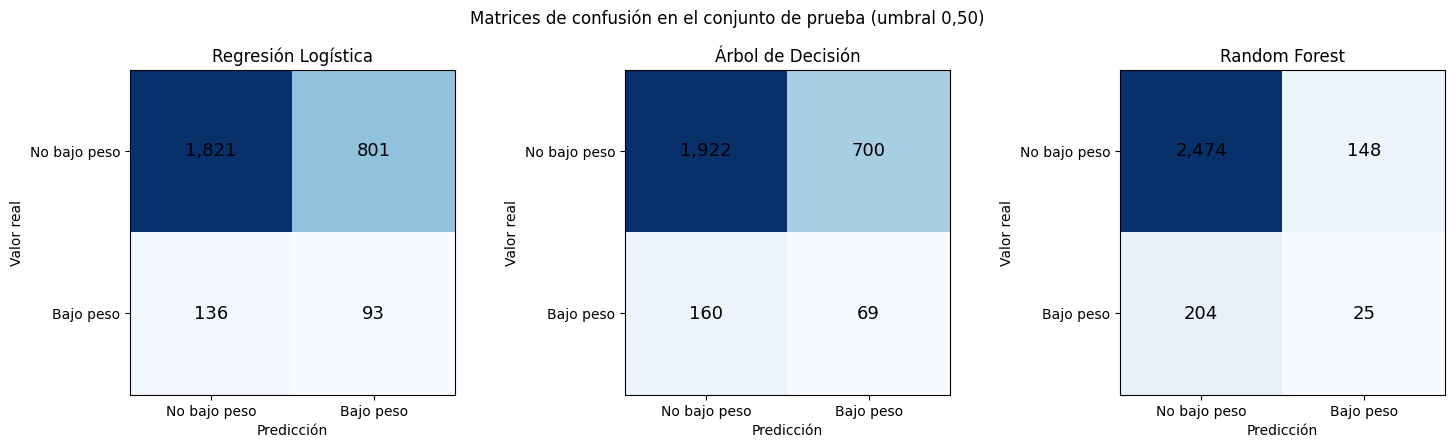

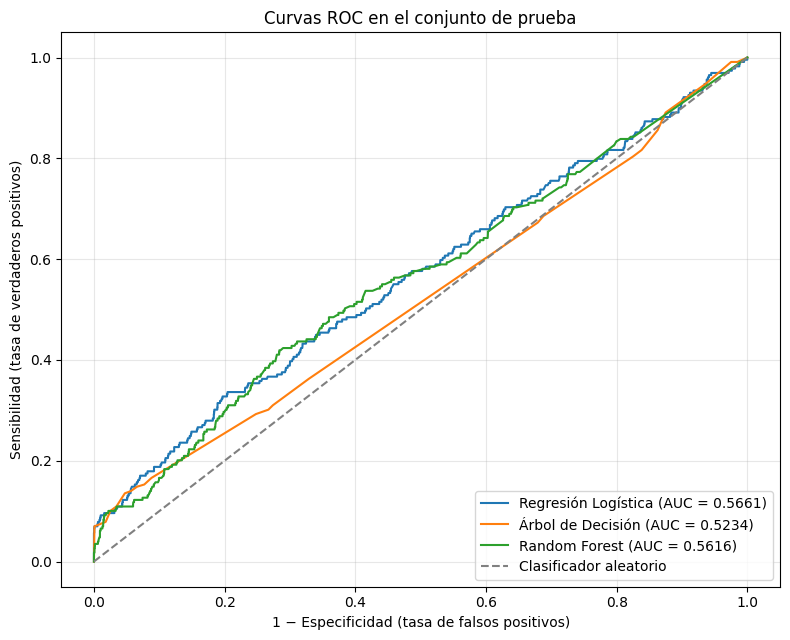

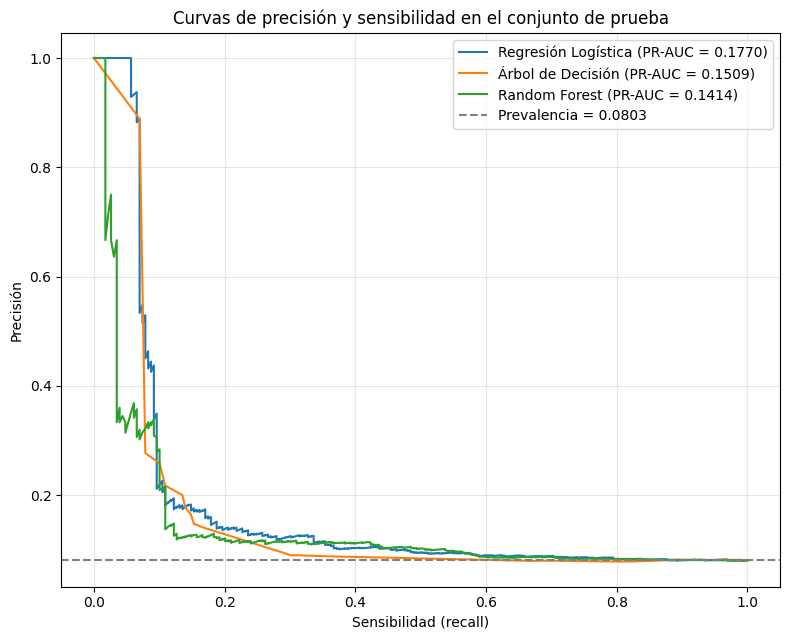


7. AJUSTE DEL UMBRAL DE DECISIÓN

Regresión Logística
  Umbral de máximo F1: 0.54 (F1 = 0.2053)
  Umbral de máximo Youden: 0.52 (J = 0.1675)

Árbol de Decisión
  Umbral de máximo F1: 0.55 (F1 = 0.2387)
  Umbral de máximo Youden: 0.49 (J = 0.1968)

Random Forest
  Umbral de máximo F1: 0.56 (F1 = 0.7812)
  Umbral de máximo Youden: 0.37 (J = 0.9149)

Umbrales seleccionados sobre el conjunto de entrenamiento:


,Modelo,Umbral_max_F1,F1_entrenamiento,Umbral_max_Youden,Youden_entrenamiento
0,Regresión Logística,0.54,0.2053,0.52,0.1675
1,Árbol de Decisión,0.55,0.2387,0.49,0.1968
2,Random Forest,0.56,0.7812,0.37,0.9149


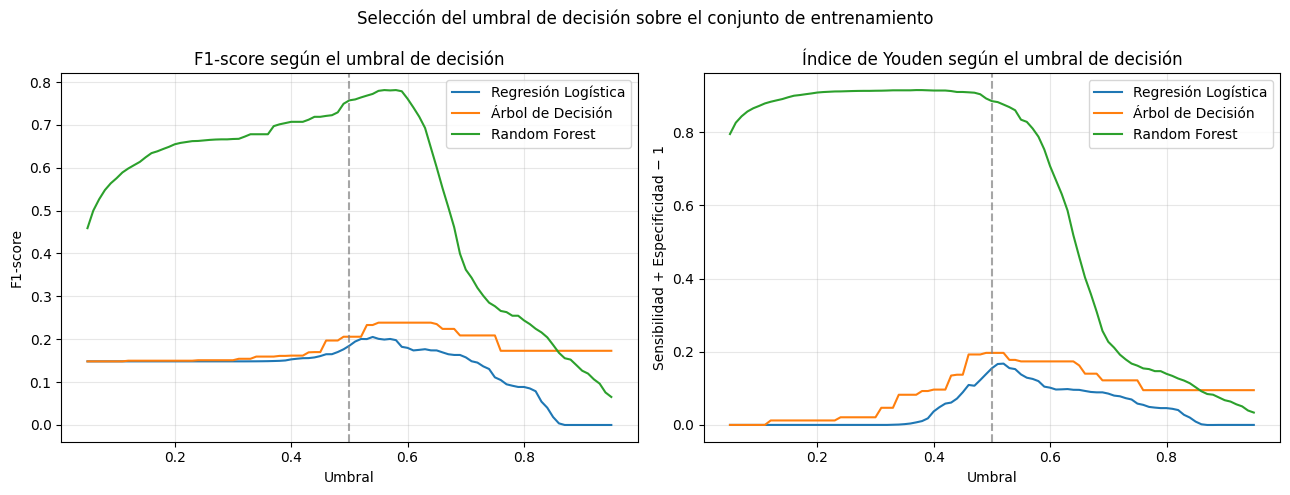


8. MÉTRICAS EN PRUEBA CON UMBRALES AJUSTADOS


,Modelo,Criterio_umbral,Umbral,ROC_AUC,PR_AUC,Sensibilidad,Especificidad,Precision,VPN,F1,Exactitud,Exactitud_balanceada,VP,FP,VN,FN
0,Regresión Logística,F1,0.54,0.5661,0.1770,0.2271,0.8772,0.1390,0.9285,0.1725,0.8250,0.5521,52,322,2300,177
1,Regresión Logística,Youden,0.52,0.5661,0.1770,0.3188,0.8066,0.1259,0.9313,0.1805,0.7675,0.5627,73,507,2115,156
2,Árbol de Decisión,F1,0.55,0.5234,0.1509,0.1485,0.9340,0.1643,0.9262,0.1560,0.8709,0.5412,34,173,2449,195
3,Árbol de Decisión,Youden,0.49,0.5234,0.1509,0.3013,0.7330,0.0897,0.9232,0.1383,0.6984,0.5172,69,700,1922,160
4,Random Forest,F1,0.56,0.5616,0.1414,0.1092,0.9577,0.1838,0.9249,0.1370,0.8895,0.5334,25,111,2511,204
5,Random Forest,Youden,0.37,0.5616,0.1414,0.1572,0.9035,0.1246,0.9247,0.1390,0.8436,0.5304,36,253,2369,193



9. SELECCIÓN DEL MODELO

Tabla comparativa (validación cruzada y conjunto de prueba):


,Modelo,ROC_AUC_CV_media,ROC_AUC_CV_desv,ROC_AUC,PR_AUC,Sensibilidad,Especificidad,Precision,F1,Exactitud_balanceada
0,Regresión Logística,0.5589,0.0232,0.5661,0.1770,0.4061,0.6945,0.1040,0.1656,0.5503
1,Árbol de Decisión,0.5685,0.0204,0.5234,0.1509,0.3013,0.7330,0.0897,0.1383,0.5172
2,Random Forest,0.5629,0.0152,0.5616,0.1414,0.1092,0.9436,0.1445,0.1244,0.5264



Modelo seleccionado: Regresión Logística

Criterio aplicado: mayor ROC-AUC en el conjunto de prueba, con revisión de PR-AUC, estabilidad en validación cruzada e interpretabilidad.

10. IMPORTANCIA DE VARIABLES

Coeficientes de la regresión logística:


,Variable,Coeficiente,Razon_de_momios
41,categoricas__MUL_PARTO_2,0.6428,1.9018
40,categoricas__MUL_PARTO_1,-0.4814,0.6179
2,numericas__N_HIJOSV,0.1511,1.1631
29,categoricas__AREA_RES_3,0.1483,1.1598
24,categoricas__NIV_EDUP_13,0.1441,1.1550
5,categoricas__EST_CIVM_2,0.1380,1.1480
33,categoricas__SEG_SOCIAL_5,0.1340,1.1434
4,categoricas__EST_CIVM_1,-0.1224,0.8848
0,numericas__EDAD_MADRE,-0.1171,0.8895
37,categoricas__IDPUEBLOIN_6,0.0918,1.0962


... (2 outputs left out)


Árbol de Decisión — diez variables con mayor importancia:


,Modelo,Variable,Importancia
40,Árbol de Decisión,categoricas__MUL_PARTO_1,0.5479
1,Árbol de Decisión,numericas__EDAD_PADRE,0.1102
0,Árbol de Decisión,numericas__EDAD_MADRE,0.0882
6,Árbol de Decisión,categoricas__EST_CIVM_5,0.0497
11,Árbol de Decisión,categoricas__NIV_EDUM_3.0,0.0392
24,Árbol de Decisión,categoricas__NIV_EDUP_13,0.0308
27,Árbol de Decisión,categoricas__AREA_RES_1,0.0285
5,Árbol de Decisión,categoricas__EST_CIVM_2,0.0280
17,Árbol de Decisión,categoricas__NIV_EDUP_2,0.0279
3,Árbol de Decisión,numericas__N_EMB,0.0205



Importancia por permutación del modelo seleccionado:


,Variable,Caida_media_ROC_AUC,Desviacion
0,EDAD_MADRE,0.0202,0.0099
10,MUL_PARTO,0.0071,0.0026
4,EST_CIVM,0.0071,0.0070
1,EDAD_PADRE,0.0053,0.0031
5,NIV_EDUM,0.0045,0.0022
2,N_HIJOSV,0.0031,0.0067
9,IDPUEBLOIN,0.0009,0.0013
8,SEG_SOCIAL,-0.0005,0.0030
7,AREA_RES,-0.0013,0.0069
3,N_EMB,-0.0030,0.0030


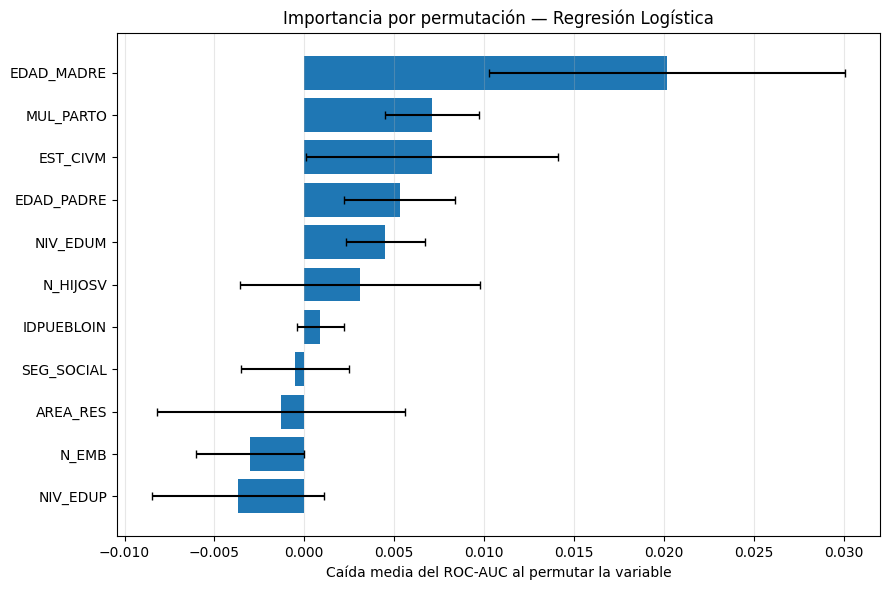

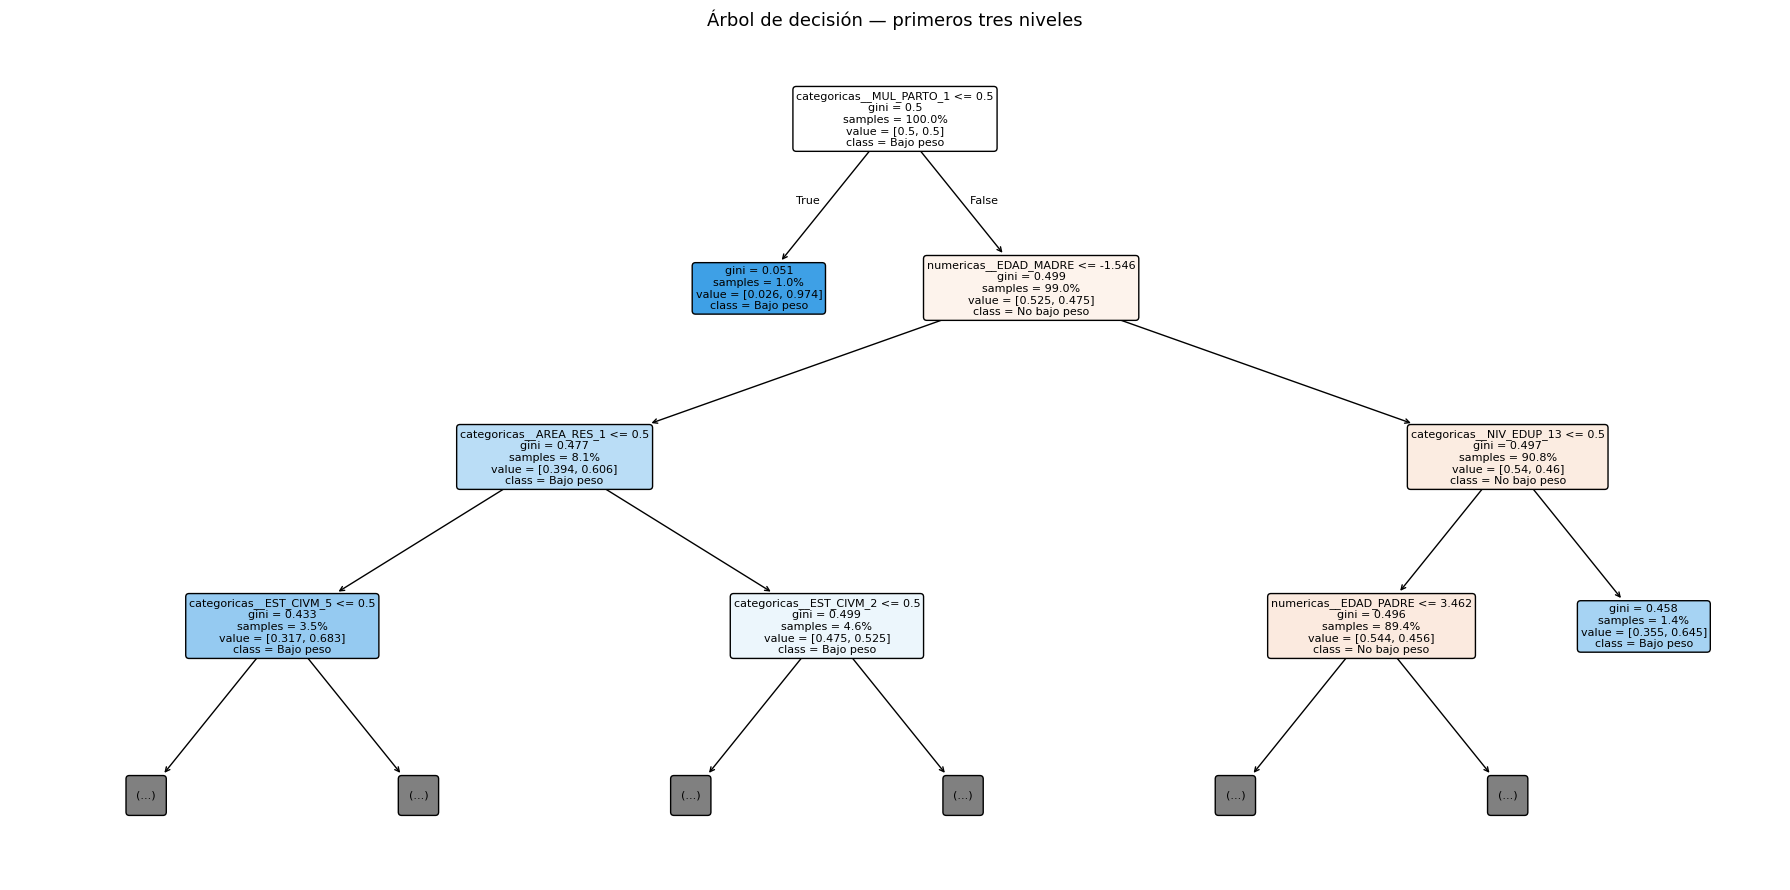


Cortes numéricos del árbol expresados en la escala original:


,Nodo,Variable,Umbral_estandarizado,Umbral_escala_original
0,2,EDAD_MADRE,-1.5459,14.5
1,10,EDAD_PADRE,-0.8965,17.5
2,12,EDAD_PADRE,-0.1701,21.5
3,17,EDAD_PADRE,3.4620,41.5
4,18,N_EMB,1.2924,1.5
5,20,EDAD_PADRE,-0.1701,21.5
6,27,EDAD_PADRE,1.2827,29.5
7,37,EDAD_PADRE,0.1931,23.5
8,40,EDAD_PADRE,-0.1701,21.5



12. ANÁLISIS DE SENSIBILIDAD SIN T_GES

RESUMEN DE LA ETAPA 6

Modelo seleccionado: Regresión Logística
ROC-AUC en prueba: 0.5661
PR-AUC en prueba: 0.1770
Sensibilidad: 0.4061
Especificidad: 0.6945
Precisión: 0.1040
F1-score: 0.1656

Umbral de máximo F1: 0.54
Umbral de máximo Youden: 0.52

Archivos generados:
- 22_metricas_prueba_umbral_050.csv
- 23_matrices_confusion.csv
- 24_umbrales_seleccionados.csv
- 25_metricas_prueba_umbral_ajustado.csv
- 26_comparativo_final_modelos.csv
- 27_coeficientes_regresion_logistica.csv
- 28_importancia_variables_arboles.csv
- 29_importancia_permutacion.csv
- 30_sensibilidad_sin_t_ges.csv
- 31_cortes_arbol_escala_original.csv
- Figura_13_matrices_confusion.png
- Figura_14_curvas_roc.png
- Figura_15_curvas_precision_sensibilidad.png
- Figura_16_ajuste_umbral.png
- Figura_17_importancia_permutacion.png
- Figura_18_arbol_decision.png
- Figura_19_sensibilidad_sin_t_ges.png

ETAPA 6 FINALIZADA.


In [11]:
# ------------------------------------------------------------
# ETAPA 6 - EVALUACIÓN
# ------------------------------------------------------------
#
# Métricas en el conjunto de prueba, matrices de confusión, curvas
# ROC y precisión-sensibilidad, ajuste del umbral de decisión,
# importancia de variables y comparación de los tres modelos.
#
# Requiere los objetos generados en la Etapa 5:
# modelos_entrenados, X_train, X_test, y_train, y_test,
# variables_numericas, variables_categoricas, predictores.
#
# ------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    classification_report
)
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree


# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

CARPETA_SALIDA = "resultados_etapa_6"

os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("=" * 70)
print("ETAPA 6 - EVALUACIÓN")
print("=" * 70)

print(f"\nRegistros de prueba: {len(X_test)}")
print(f"Casos de bajo peso en prueba: {int(y_test.sum())}")
print(f"Casos sin bajo peso en prueba: {int((y_test == 0).sum())}")


# ------------------------------------------------------------
# 2. FUNCIÓN DE CÁLCULO DE MÉTRICAS
# ------------------------------------------------------------
#
# Se calcula especificidad de forma explícita porque scikit-learn
# no la incluye como métrica directa.

def calcular_metricas(y_real, y_predicho, y_probabilidad):

    matriz = confusion_matrix(y_real, y_predicho, labels=[0, 1])

    vn, fp, fn, vp = matriz.ravel()

    especificidad = vn / (vn + fp) if (vn + fp) > 0 else np.nan
    vpn = vn / (vn + fn) if (vn + fn) > 0 else np.nan

    return {
        "Exactitud": accuracy_score(y_real, y_predicho),
        "Exactitud_balanceada": balanced_accuracy_score(
            y_real, y_predicho
        ),
        "Sensibilidad": recall_score(y_real, y_predicho, zero_division=0),
        "Especificidad": especificidad,
        "Precision": precision_score(y_real, y_predicho, zero_division=0),
        "VPN": vpn,
        "F1": f1_score(y_real, y_predicho, zero_division=0),
        "ROC_AUC": roc_auc_score(y_real, y_probabilidad),
        "PR_AUC": average_precision_score(y_real, y_probabilidad),
        "VP": int(vp),
        "FP": int(fp),
        "VN": int(vn),
        "FN": int(fn)
    }


# ------------------------------------------------------------
# 3. EVALUACIÓN EN EL CONJUNTO DE PRUEBA (UMBRAL 0,5)
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. MÉTRICAS EN EL CONJUNTO DE PRUEBA (UMBRAL 0,50)")
print("=" * 70)

probabilidades = {}
predicciones = {}
filas_metricas = []

for nombre, modelo in modelos_entrenados.items():

    probabilidad = modelo.predict_proba(X_test)[:, 1]
    prediccion = (probabilidad >= 0.5).astype(int)

    probabilidades[nombre] = probabilidad
    predicciones[nombre] = prediccion

    metricas = calcular_metricas(y_test, prediccion, probabilidad)
    metricas["Modelo"] = nombre

    filas_metricas.append(metricas)

    print(f"\n{nombre}")
    print(
        classification_report(
            y_test,
            prediccion,
            target_names=["No bajo peso", "Bajo peso"],
            digits=4,
            zero_division=0
        )
    )

columnas_orden = [
    "Modelo",
    "ROC_AUC",
    "PR_AUC",
    "Sensibilidad",
    "Especificidad",
    "Precision",
    "VPN",
    "F1",
    "Exactitud",
    "Exactitud_balanceada",
    "VP",
    "FP",
    "VN",
    "FN"
]

tabla_metricas = pd.DataFrame(filas_metricas)[columnas_orden].round(4)

print("\nTabla de métricas en el conjunto de prueba:")
display(tabla_metricas)

tabla_metricas.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "22_metricas_prueba_umbral_050.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4. MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("4. MATRICES DE CONFUSIÓN")
print("=" * 70)

fig, ejes = plt.subplots(
    1,
    len(modelos_entrenados),
    figsize=(5 * len(modelos_entrenados), 4.5)
)

if len(modelos_entrenados) == 1:
    ejes = [ejes]

filas_matrices = []

for eje, (nombre, prediccion) in zip(ejes, predicciones.items()):

    matriz = confusion_matrix(y_test, prediccion, labels=[0, 1])

    eje.imshow(matriz, cmap="Blues")

    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Valor real")

    eje.set_xticks([0, 1])
    eje.set_yticks([0, 1])
    eje.set_xticklabels(["No bajo peso", "Bajo peso"])
    eje.set_yticklabels(["No bajo peso", "Bajo peso"])

    for i in range(2):
        for j in range(2):
            eje.text(
                j,
                i,
                f"{matriz[i, j]:,}",
                ha="center",
                va="center",
                fontsize=13,
                color="black"
            )

    vn, fp, fn, vp = matriz.ravel()

    filas_matrices.append({
        "Modelo": nombre,
        "Verdaderos_negativos": int(vn),
        "Falsos_positivos": int(fp),
        "Falsos_negativos": int(fn),
        "Verdaderos_positivos": int(vp)
    })

    print(f"\n{nombre}")
    print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")

fig.suptitle(
    "Matrices de confusión en el conjunto de prueba (umbral 0,50)"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_13_matrices_confusion.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

pd.DataFrame(filas_matrices).to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "23_matrices_confusion.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. CURVAS ROC
# ------------------------------------------------------------

plt.figure(figsize=(8, 6.5))

for nombre, probabilidad in probabilidades.items():

    fpr, tpr, _ = roc_curve(y_test, probabilidad)
    auc = roc_auc_score(y_test, probabilidad)

    plt.plot(
        fpr,
        tpr,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificador aleatorio"
)

plt.xlabel("1 − Especificidad (tasa de falsos positivos)")
plt.ylabel("Sensibilidad (tasa de verdaderos positivos)")
plt.title("Curvas ROC en el conjunto de prueba")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_14_curvas_roc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. CURVAS PRECISIÓN-SENSIBILIDAD
# ------------------------------------------------------------
#
# Con clases desbalanceadas esta curva resulta más informativa que
# la curva ROC, porque depende de la prevalencia de la clase positiva.

prevalencia = y_test.mean()

plt.figure(figsize=(8, 6.5))

for nombre, probabilidad in probabilidades.items():

    precision_curva, recall_curva, _ = precision_recall_curve(
        y_test, probabilidad
    )

    pr_auc = average_precision_score(y_test, probabilidad)

    plt.plot(
        recall_curva,
        precision_curva,
        label=f"{nombre} (PR-AUC = {pr_auc:.4f})"
    )

plt.axhline(
    prevalencia,
    linestyle="--",
    color="gray",
    label=f"Prevalencia = {prevalencia:.4f}"
)

plt.xlabel("Sensibilidad (recall)")
plt.ylabel("Precisión")
plt.title(
    "Curvas de precisión y sensibilidad en el conjunto de prueba"
)
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_15_curvas_precision_sensibilidad.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. AJUSTE DEL UMBRAL DE DECISIÓN
# ------------------------------------------------------------
#
# El umbral se selecciona sobre el conjunto de ENTRENAMIENTO para no
# utilizar el conjunto de prueba en la decisión. Se reportan dos
# criterios: máximo F1 y máximo índice de Youden (J = Sen + Esp − 1).

print("\n" + "=" * 70)
print("7. AJUSTE DEL UMBRAL DE DECISIÓN")
print("=" * 70)

rejilla_umbrales = np.arange(0.05, 0.96, 0.01)

umbrales_seleccionados = {}
filas_umbral = []
curvas_umbral = {}

for nombre, modelo in modelos_entrenados.items():

    probabilidad_train = modelo.predict_proba(X_train)[:, 1]

    f1_por_umbral = []
    youden_por_umbral = []

    for umbral in rejilla_umbrales:

        prediccion_train = (probabilidad_train >= umbral).astype(int)

        f1_por_umbral.append(
            f1_score(y_train, prediccion_train, zero_division=0)
        )

        matriz = confusion_matrix(
            y_train, prediccion_train, labels=[0, 1]
        )

        vn, fp, fn, vp = matriz.ravel()

        sensibilidad = vp / (vp + fn) if (vp + fn) > 0 else 0.0
        especificidad = vn / (vn + fp) if (vn + fp) > 0 else 0.0

        youden_por_umbral.append(sensibilidad + especificidad - 1)

    f1_por_umbral = np.array(f1_por_umbral)
    youden_por_umbral = np.array(youden_por_umbral)

    umbral_f1 = rejilla_umbrales[int(f1_por_umbral.argmax())]
    umbral_youden = rejilla_umbrales[int(youden_por_umbral.argmax())]

    umbrales_seleccionados[nombre] = {
        "F1": float(umbral_f1),
        "Youden": float(umbral_youden)
    }

    curvas_umbral[nombre] = (f1_por_umbral, youden_por_umbral)

    filas_umbral.append({
        "Modelo": nombre,
        "Umbral_max_F1": round(float(umbral_f1), 2),
        "F1_entrenamiento": round(float(f1_por_umbral.max()), 4),
        "Umbral_max_Youden": round(float(umbral_youden), 2),
        "Youden_entrenamiento": round(float(youden_por_umbral.max()), 4)
    })

    print(
        f"\n{nombre}"
        f"\n  Umbral de máximo F1: {umbral_f1:.2f} "
        f"(F1 = {f1_por_umbral.max():.4f})"
        f"\n  Umbral de máximo Youden: {umbral_youden:.2f} "
        f"(J = {youden_por_umbral.max():.4f})"
    )

tabla_umbral = pd.DataFrame(filas_umbral)

print("\nUmbrales seleccionados sobre el conjunto de entrenamiento:")
display(tabla_umbral)

tabla_umbral.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "24_umbrales_seleccionados.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for nombre, (f1_valores, youden_valores) in curvas_umbral.items():
    ejes[0].plot(rejilla_umbrales, f1_valores, label=nombre)
    ejes[1].plot(rejilla_umbrales, youden_valores, label=nombre)

ejes[0].axvline(0.5, linestyle="--", color="gray", alpha=0.7)
ejes[0].set_title("F1-score según el umbral de decisión")
ejes[0].set_xlabel("Umbral")
ejes[0].set_ylabel("F1-score")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

ejes[1].axvline(0.5, linestyle="--", color="gray", alpha=0.7)
ejes[1].set_title("Índice de Youden según el umbral de decisión")
ejes[1].set_xlabel("Umbral")
ejes[1].set_ylabel("Sensibilidad + Especificidad − 1")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

fig.suptitle(
    "Selección del umbral de decisión sobre el conjunto de entrenamiento"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_16_ajuste_umbral.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. MÉTRICAS EN PRUEBA CON LOS UMBRALES AJUSTADOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8. MÉTRICAS EN PRUEBA CON UMBRALES AJUSTADOS")
print("=" * 70)

filas_ajustadas = []

for nombre, probabilidad in probabilidades.items():

    for criterio in ["F1", "Youden"]:

        umbral = umbrales_seleccionados[nombre][criterio]

        prediccion = (probabilidad >= umbral).astype(int)

        metricas = calcular_metricas(y_test, prediccion, probabilidad)

        metricas["Modelo"] = nombre
        metricas["Criterio_umbral"] = criterio
        metricas["Umbral"] = round(umbral, 2)

        filas_ajustadas.append(metricas)

columnas_ajustadas = (
    ["Modelo", "Criterio_umbral", "Umbral"]
    + columnas_orden[1:]
)

tabla_ajustada = pd.DataFrame(filas_ajustadas)[
    columnas_ajustadas
].round(4)

display(tabla_ajustada)

tabla_ajustada.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "25_metricas_prueba_umbral_ajustado.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 9. SELECCIÓN DEL MODELO
# ------------------------------------------------------------
#
# Criterio definido antes de la comparación: se prioriza ROC-AUC como
# medida de discriminación independiente del umbral y, en caso de
# diferencias pequeñas, se considera PR-AUC por el desbalance de
# clases, la estabilidad en validación cruzada y la interpretabilidad.

print("\n" + "=" * 70)
print("9. SELECCIÓN DEL MODELO")
print("=" * 70)

tabla_comparativa = tabla_metricas.merge(
    tabla_validacion[
        ["Modelo", "roc_auc_media", "roc_auc_desv", "f1_media", "f1_desv"]
    ].rename(columns={
        "roc_auc_media": "ROC_AUC_CV_media",
        "roc_auc_desv": "ROC_AUC_CV_desv",
        "f1_media": "F1_CV_media",
        "f1_desv": "F1_CV_desv"
    }),
    on="Modelo",
    how="left"
)

tabla_comparativa = tabla_comparativa[[
    "Modelo",
    "ROC_AUC_CV_media",
    "ROC_AUC_CV_desv",
    "ROC_AUC",
    "PR_AUC",
    "Sensibilidad",
    "Especificidad",
    "Precision",
    "F1",
    "Exactitud_balanceada"
]].round(4)

print("\nTabla comparativa (validación cruzada y conjunto de prueba):")
display(tabla_comparativa)

tabla_comparativa.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "26_comparativo_final_modelos.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

modelo_seleccionado = tabla_comparativa.loc[
    tabla_comparativa["ROC_AUC"].idxmax(),
    "Modelo"
]

print(f"\nModelo seleccionado: {modelo_seleccionado}")

print(
    "\nCriterio aplicado: mayor ROC-AUC en el conjunto de prueba, "
    "con revisión de PR-AUC, estabilidad en validación cruzada e "
    "interpretabilidad."
)


# ------------------------------------------------------------
# 10. IMPORTANCIA DE VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("10. IMPORTANCIA DE VARIABLES")
print("=" * 70)

# 10.1 Coeficientes y razones de momios de la regresión logística.
#
# Las variables numéricas fueron estandarizadas, por lo que la razón
# de momios se interpreta por cada desviación estándar de aumento.

nombre_logistica = "Regresión Logística"

if nombre_logistica in modelos_entrenados:

    flujo_logistico = modelos_entrenados[nombre_logistica]

    nombres_variables = (
        flujo_logistico
        .named_steps["preprocesamiento"]
        .get_feature_names_out()
    )

    coeficientes = (
        flujo_logistico
        .named_steps["modelo"]
        .coef_[0]
    )

    tabla_coeficientes = pd.DataFrame({
        "Variable": nombres_variables,
        "Coeficiente": coeficientes,
        "Razon_de_momios": np.exp(coeficientes)
    })

    tabla_coeficientes["Magnitud"] = tabla_coeficientes[
        "Coeficiente"
    ].abs()

    tabla_coeficientes = tabla_coeficientes.sort_values(
        "Magnitud",
        ascending=False
    ).drop(columns="Magnitud").round(4)

    print("\nCoeficientes de la regresión logística:")
    display(tabla_coeficientes.head(20))

    tabla_coeficientes.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "27_coeficientes_regresion_logistica.csv"
        ),
        index=False,
        encoding="utf-8-sig"
    )


# 10.2 Importancia por reducción de impureza en árbol y Random Forest.

filas_importancia = []

for nombre in ["Árbol de Decisión", "Random Forest"]:

    if nombre not in modelos_entrenados:
        continue

    flujo = modelos_entrenados[nombre]

    nombres_variables = (
        flujo
        .named_steps["preprocesamiento"]
        .get_feature_names_out()
    )

    importancias = flujo.named_steps["modelo"].feature_importances_

    for variable, importancia in zip(nombres_variables, importancias):
        filas_importancia.append({
            "Modelo": nombre,
            "Variable": variable,
            "Importancia": importancia
        })

tabla_importancia = pd.DataFrame(filas_importancia)

if len(tabla_importancia):

    tabla_importancia = tabla_importancia.sort_values(
        ["Modelo", "Importancia"],
        ascending=[True, False]
    ).round(4)

    print("\nImportancia de variables (árbol y Random Forest):")

    for nombre in tabla_importancia["Modelo"].unique():
        print(f"\n{nombre} — diez variables con mayor importancia:")
        display(
            tabla_importancia[
                tabla_importancia["Modelo"] == nombre
            ].head(10)
        )

    tabla_importancia.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "28_importancia_variables_arboles.csv"
        ),
        index=False,
        encoding="utf-8-sig"
    )


# 10.3 Importancia por permutación del modelo seleccionado.
#
# Se calcula sobre el conjunto de prueba y es comparable entre
# modelos porque mide la caída del ROC-AUC al permutar cada variable.

print("\nImportancia por permutación del modelo seleccionado:")

resultado_permutacion = permutation_importance(
    modelos_entrenados[modelo_seleccionado],
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1
)

tabla_permutacion = pd.DataFrame({
    "Variable": predictores,
    "Caida_media_ROC_AUC": resultado_permutacion.importances_mean,
    "Desviacion": resultado_permutacion.importances_std
}).sort_values(
    "Caida_media_ROC_AUC",
    ascending=False
).round(4)

display(tabla_permutacion)

tabla_permutacion.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "29_importancia_permutacion.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

plt.figure(figsize=(9, 6))

datos_grafico = tabla_permutacion.iloc[::-1]

plt.barh(
    datos_grafico["Variable"],
    datos_grafico["Caida_media_ROC_AUC"],
    xerr=datos_grafico["Desviacion"],
    capsize=3
)

plt.xlabel("Caída media del ROC-AUC al permutar la variable")
plt.title(
    f"Importancia por permutación — {modelo_seleccionado}"
)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        CARPETA_SALIDA,
        "Figura_17_importancia_permutacion.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 11. REGLAS DEL ÁRBOL DE DECISIÓN
# ------------------------------------------------------------
#
# El árbol se grafica con profundidad limitada para que las reglas
# resulten legibles en el documento.

if "Árbol de Decisión" in modelos_entrenados:

    flujo_arbol = modelos_entrenados["Árbol de Decisión"]

    nombres_arbol = (
        flujo_arbol
        .named_steps["preprocesamiento"]
        .get_feature_names_out()
    )

    plt.figure(figsize=(18, 9))

    plot_tree(
        flujo_arbol.named_steps["modelo"],
        feature_names=nombres_arbol,
        class_names=["No bajo peso", "Bajo peso"],
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8,
        proportion=True
    )

    plt.title(
        "Árbol de decisión — primeros tres niveles",
        fontsize=13
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_18_arbol_decision.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Los cortes del árbol se expresan en unidades estandarizadas.
    # Se convierten a la escala original para facilitar la lectura.

    escalador_ajustado = (
        flujo_arbol
        .named_steps["preprocesamiento"]
        .named_transformers_["numericas"]
        .named_steps["escalador"]
    )

    medias_originales = dict(
        zip(variables_numericas, escalador_ajustado.mean_)
    )

    desviaciones_originales = dict(
        zip(variables_numericas, np.sqrt(escalador_ajustado.var_))
    )

    arbol_ajustado = flujo_arbol.named_steps["modelo"]
    nombres_nodos = list(nombres_arbol)

    filas_cortes = []

    for nodo in range(arbol_ajustado.tree_.node_count):

        indice_variable = arbol_ajustado.tree_.feature[nodo]

        if indice_variable < 0:
            continue

        nombre_completo = nombres_nodos[indice_variable]
        umbral_estandarizado = arbol_ajustado.tree_.threshold[nodo]

        nombre_base = nombre_completo.split("__")[-1]

        if nombre_base in medias_originales:

            valor_original = (
                medias_originales[nombre_base]
                + umbral_estandarizado
                * desviaciones_originales[nombre_base]
            )

            filas_cortes.append({
                "Nodo": nodo,
                "Variable": nombre_base,
                "Umbral_estandarizado": round(
                    float(umbral_estandarizado), 4
                ),
                "Umbral_escala_original": round(
                    float(valor_original), 2
                )
            })

    if filas_cortes:

        tabla_cortes = pd.DataFrame(filas_cortes)

        print(
            "\nCortes numéricos del árbol expresados en la escala "
            "original:"
        )
        display(tabla_cortes)

        tabla_cortes.to_csv(
            os.path.join(
                CARPETA_SALIDA,
                "31_cortes_arbol_escala_original.csv"
            ),
            index=False,
            encoding="utf-8-sig"
        )


# ------------------------------------------------------------
# 12. ANÁLISIS DE SENSIBILIDAD SIN T_GES
# ------------------------------------------------------------
#
# T_GES fue la variable con mayor asociación en la Etapa 4. Este
# análisis cuantifica cuánto del desempeño depende de ella y
# documenta el comportamiento del modelo si la variable no estuviera
# disponible en el momento de la predicción.

print("\n" + "=" * 70)
print("12. ANÁLISIS DE SENSIBILIDAD SIN T_GES")
print("=" * 70)

from sklearn.base import clone

if "T_GES" in variables_numericas:

    numericas_sin_tges = [
        v for v in variables_numericas if v != "T_GES"
    ]

    predictores_sin_tges = numericas_sin_tges + variables_categoricas

    transformador_numerico_sin = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ])

    transformador_categorico_sin = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=FRECUENCIA_MINIMA_CATEGORIA
        ))
    ])

    preprocesador_sin_tges = ColumnTransformer(
        transformers=[
            ("numericas", transformador_numerico_sin, numericas_sin_tges),
            ("categoricas", transformador_categorico_sin,
             variables_categoricas)
        ],
        remainder="drop"
    )

    filas_sensibilidad = []

    for nombre, flujo in modelos_entrenados.items():

        estimador = clone(flujo.named_steps["modelo"])

        flujo_sin_tges = Pipeline(steps=[
            ("preprocesamiento", preprocesador_sin_tges),
            ("modelo", estimador)
        ])

        flujo_sin_tges.fit(
            X_train[predictores_sin_tges], y_train
        )

        probabilidad_sin = flujo_sin_tges.predict_proba(
            X_test[predictores_sin_tges]
        )[:, 1]

        prediccion_sin = (probabilidad_sin >= 0.5).astype(int)

        metricas_sin = calcular_metricas(
            y_test, prediccion_sin, probabilidad_sin
        )

        roc_con = float(
            tabla_metricas.loc[
                tabla_metricas["Modelo"] == nombre, "ROC_AUC"
            ].iloc[0]
        )

        filas_sensibilidad.append({
            "Modelo": nombre,
            "ROC_AUC_con_T_GES": round(roc_con, 4),
            "ROC_AUC_sin_T_GES": round(metricas_sin["ROC_AUC"], 4),
            "Diferencia": round(
                roc_con - metricas_sin["ROC_AUC"], 4
            ),
            "Sensibilidad_sin_T_GES": round(
                metricas_sin["Sensibilidad"], 4
            ),
            "Especificidad_sin_T_GES": round(
                metricas_sin["Especificidad"], 4
            ),
            "F1_sin_T_GES": round(metricas_sin["F1"], 4)
        })

    tabla_sensibilidad = pd.DataFrame(filas_sensibilidad)

    print("\nComparación del desempeño con y sin T_GES:")
    display(tabla_sensibilidad)

    tabla_sensibilidad.to_csv(
        os.path.join(
            CARPETA_SALIDA,
            "30_sensibilidad_sin_t_ges.csv"
        ),
        index=False,
        encoding="utf-8-sig"
    )

    posiciones_sens = np.arange(len(tabla_sensibilidad))
    ancho_sens = 0.35

    plt.figure(figsize=(9, 5.5))

    plt.bar(
        posiciones_sens - ancho_sens / 2,
        tabla_sensibilidad["ROC_AUC_con_T_GES"],
        ancho_sens,
        label="Con T_GES"
    )

    plt.bar(
        posiciones_sens + ancho_sens / 2,
        tabla_sensibilidad["ROC_AUC_sin_T_GES"],
        ancho_sens,
        label="Sin T_GES"
    )

    plt.xticks(posiciones_sens, tabla_sensibilidad["Modelo"])
    plt.ylim(0, 1)
    plt.ylabel("ROC-AUC en el conjunto de prueba")
    plt.title(
        "Análisis de sensibilidad: desempeño con y sin edad gestacional"
    )
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            CARPETA_SALIDA,
            "Figura_19_sensibilidad_sin_t_ges.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# 13. RESUMEN DE LA ETAPA 6
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESUMEN DE LA ETAPA 6")
print("=" * 70)

fila_seleccionado = tabla_metricas[
    tabla_metricas["Modelo"] == modelo_seleccionado
].iloc[0]

print(f"\nModelo seleccionado: {modelo_seleccionado}")
print(f"ROC-AUC en prueba: {fila_seleccionado['ROC_AUC']:.4f}")
print(f"PR-AUC en prueba: {fila_seleccionado['PR_AUC']:.4f}")
print(f"Sensibilidad: {fila_seleccionado['Sensibilidad']:.4f}")
print(f"Especificidad: {fila_seleccionado['Especificidad']:.4f}")
print(f"Precisión: {fila_seleccionado['Precision']:.4f}")
print(f"F1-score: {fila_seleccionado['F1']:.4f}")

print(
    f"\nUmbral de máximo F1: "
    f"{umbrales_seleccionados[modelo_seleccionado]['F1']:.2f}"
)
print(
    f"Umbral de máximo Youden: "
    f"{umbrales_seleccionados[modelo_seleccionado]['Youden']:.2f}"
)

print("\nArchivos generados:")

for archivo in sorted(os.listdir(CARPETA_SALIDA)):
    print("-", archivo)

print("\nETAPA 6 FINALIZADA.")
